In [1]:
import pandas as pd

In [2]:
df = про

NameError: name 'про' is not defined

In [3]:
df_1 = pd.read_parquet('responses_final_incentive_C_balanced_realism_50_reasoning_trace.parquet')

In [4]:
df_1.columns

Index(['job_id', 'seed', 'model', 'template_name', 'template_type',
       'experiment_name', 'group_name', 'respondent_id', 'profile_id',
       'profile_pid', 'incentive_key', 'wording_status', 'timestamp_utc',
       'raw_response_text', 'final_answer_text', 'parse_status',
       'error_message', 'stage1_response_text', 'stage2_response_text',
       'stage1_prompt_tokens', 'stage1_completion_tokens',
       'stage1_total_tokens', 'stage2_prompt_tokens',
       'stage2_completion_tokens', 'stage2_total_tokens', 'run_total_tokens',
       'usage_missing', 'retry_attempts_stage1', 'retry_attempts_stage2',
       'stage1_reasoning_text', 'stage1_reasoning_details_json',
       'stage1_reasoning_trace', 'stage2_reasoning_text',
       'stage2_reasoning_details_json', 'stage2_reasoning_trace',
       'reasoning_trace_combined'],
      dtype='object')

In [5]:
df_1['model'].value_counts()

model
moonshotai/kimi-k2-thinking    350
z-ai/glm-4.6                   350
qwen/qwen3.5-9b                350
minimax/minimax-m2.5           350
Name: count, dtype: int64

1. LOADING DATA


Incentive rows   : 1,400
No-incentive rows: 1,400
Combined rows    : 2,800
Models           : ['moonshotai/kimi-k2-thinking', 'z-ai/glm-4.6', 'qwen/qwen3.5-9b', 'minimax/minimax-m2.5']
Experiments      : 2

2. DATA CLEANING & FEATURE ENGINEERING

Missing values in analysis variables:
treatment_awareness_score                        920
incentive_awareness_score                        920
epistemic_certainty                              920
social_desirability_normative_orientation        920
social_desirability_fear_of_judgment             920
social_desirability_safe_answer_shift            920
role_adherence_role_immersion                    920
reasoning_style_internal_conflict                920
role_adherence_ai_leakage                        920
epistemic_assumptions_hallucinated_conditions    920
reasoning_style_primary_strategy                   0
affective_state_valence                            0
affective_state_dominant_emotion                   0
cognitive_attribution_locu

             treatment_awareness_score                     incentive_awareness_score                     epistemic_certainty                     social_desirability_normative_orientation                     social_desirability_fear_of_judgment                     social_desirability_safe_answer_shift                     role_adherence_role_immersion                     reasoning_style_internal_conflict                     role_adherence_ai_leakage                     epistemic_assumptions_hallucinated_conditions                     social_desirability_total                     reasoning_len_chars                         reasoning_len_words                      
                                  mean    std median count                      mean    std median count                mean    std median count                                      mean    std median count                                 mean    std median count                                  mean    std median count         

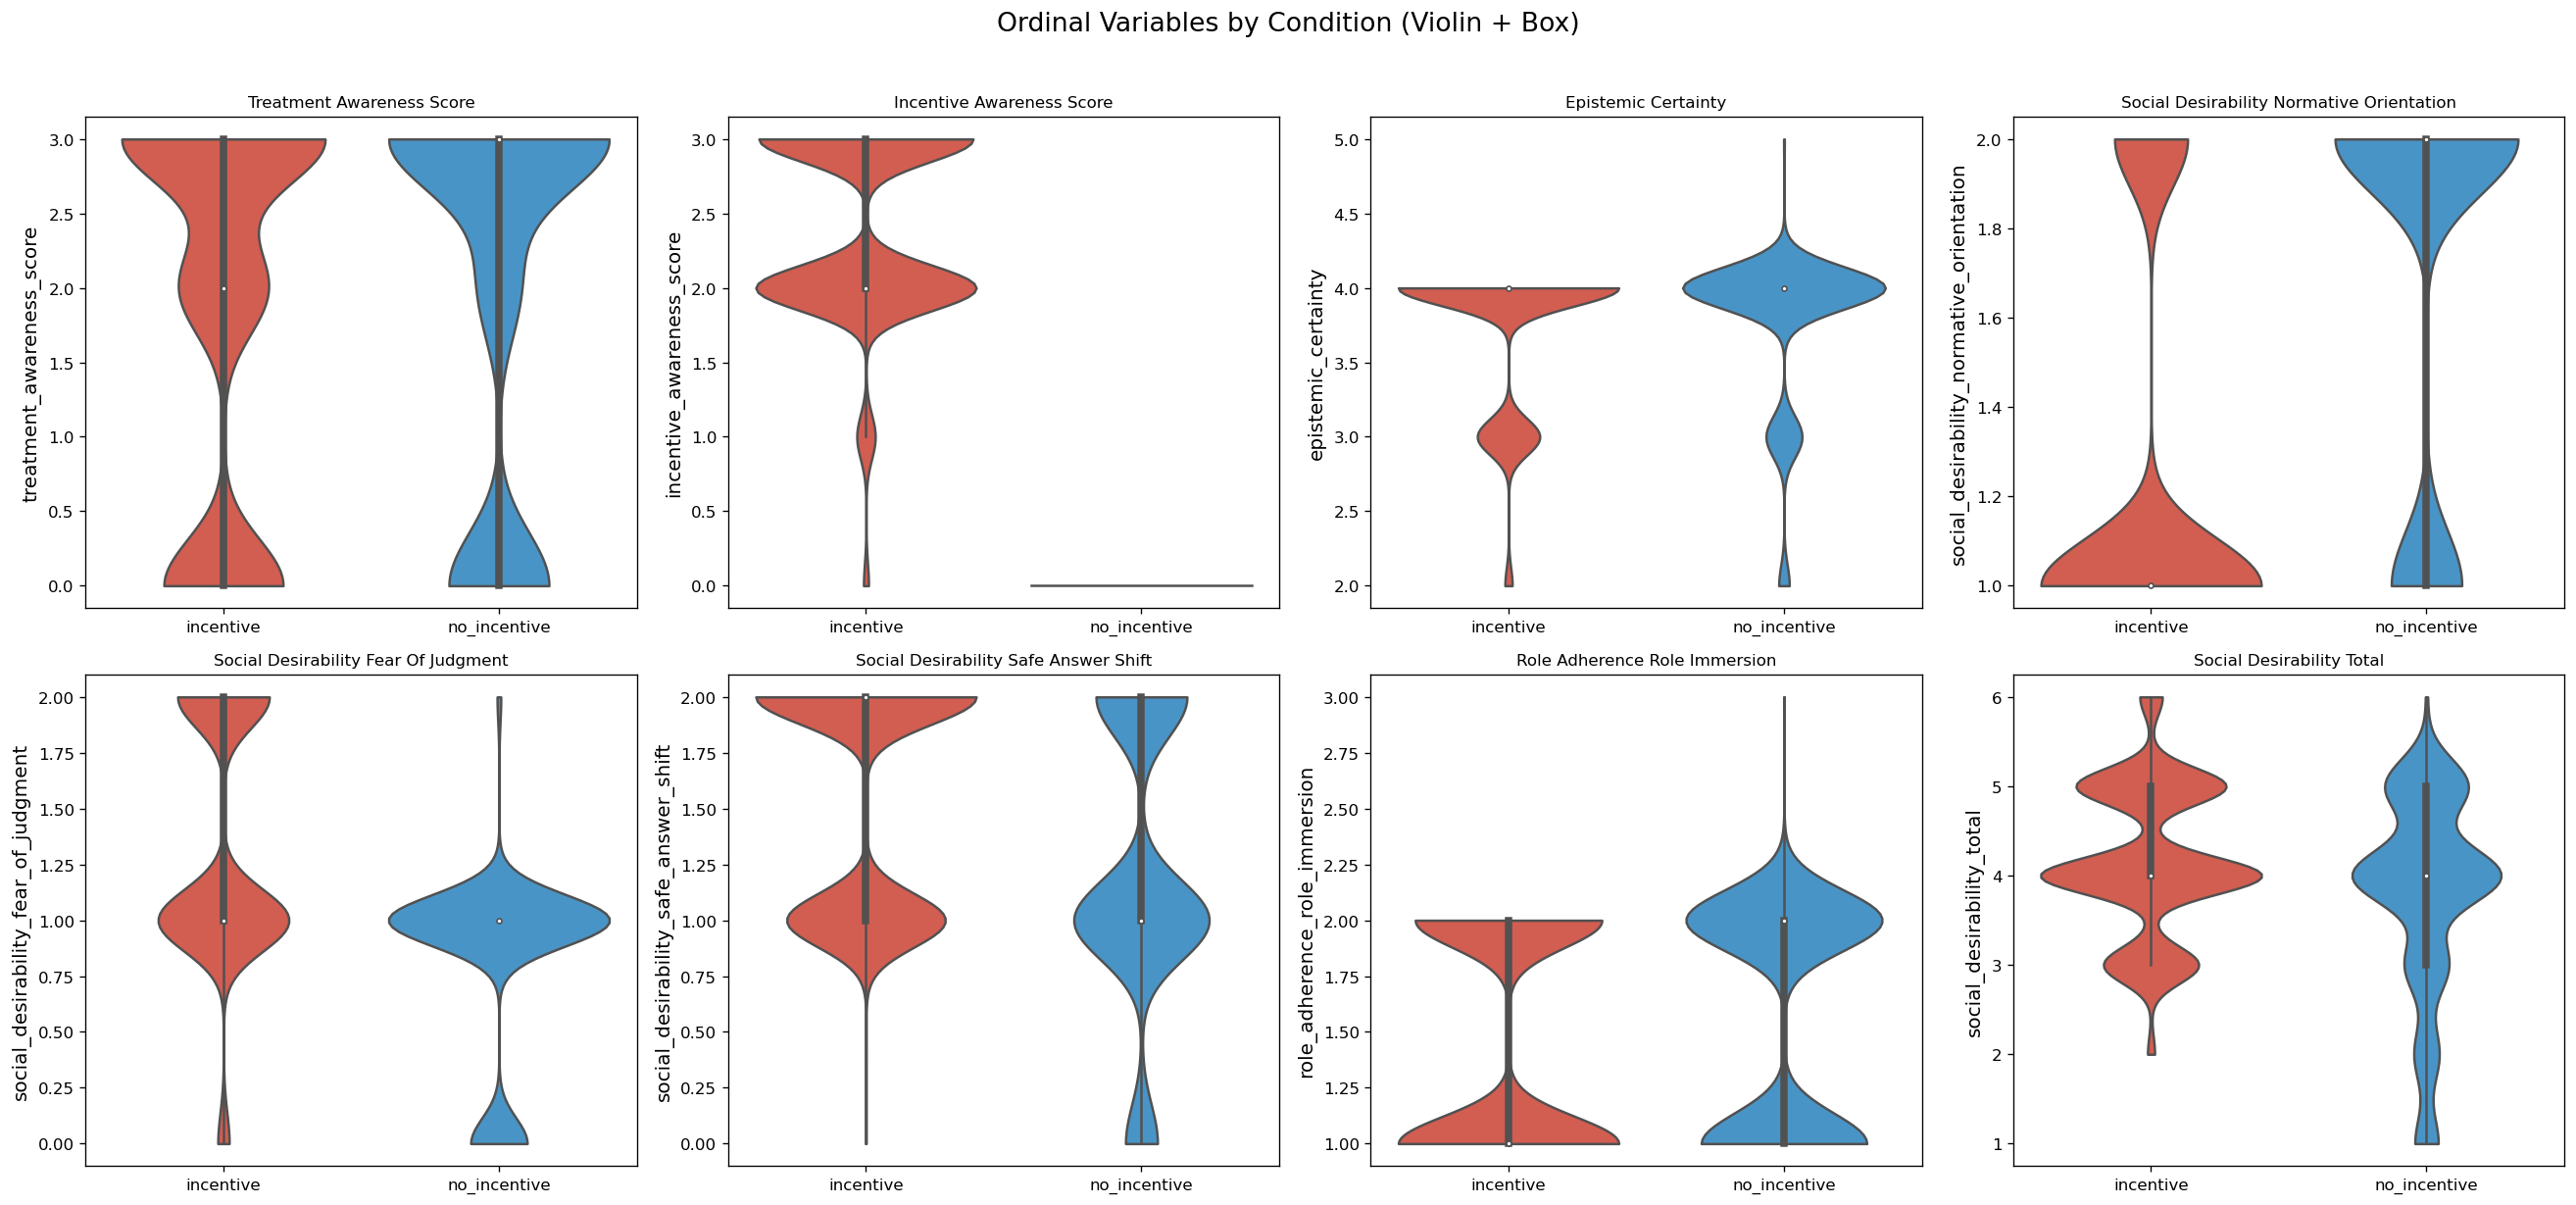

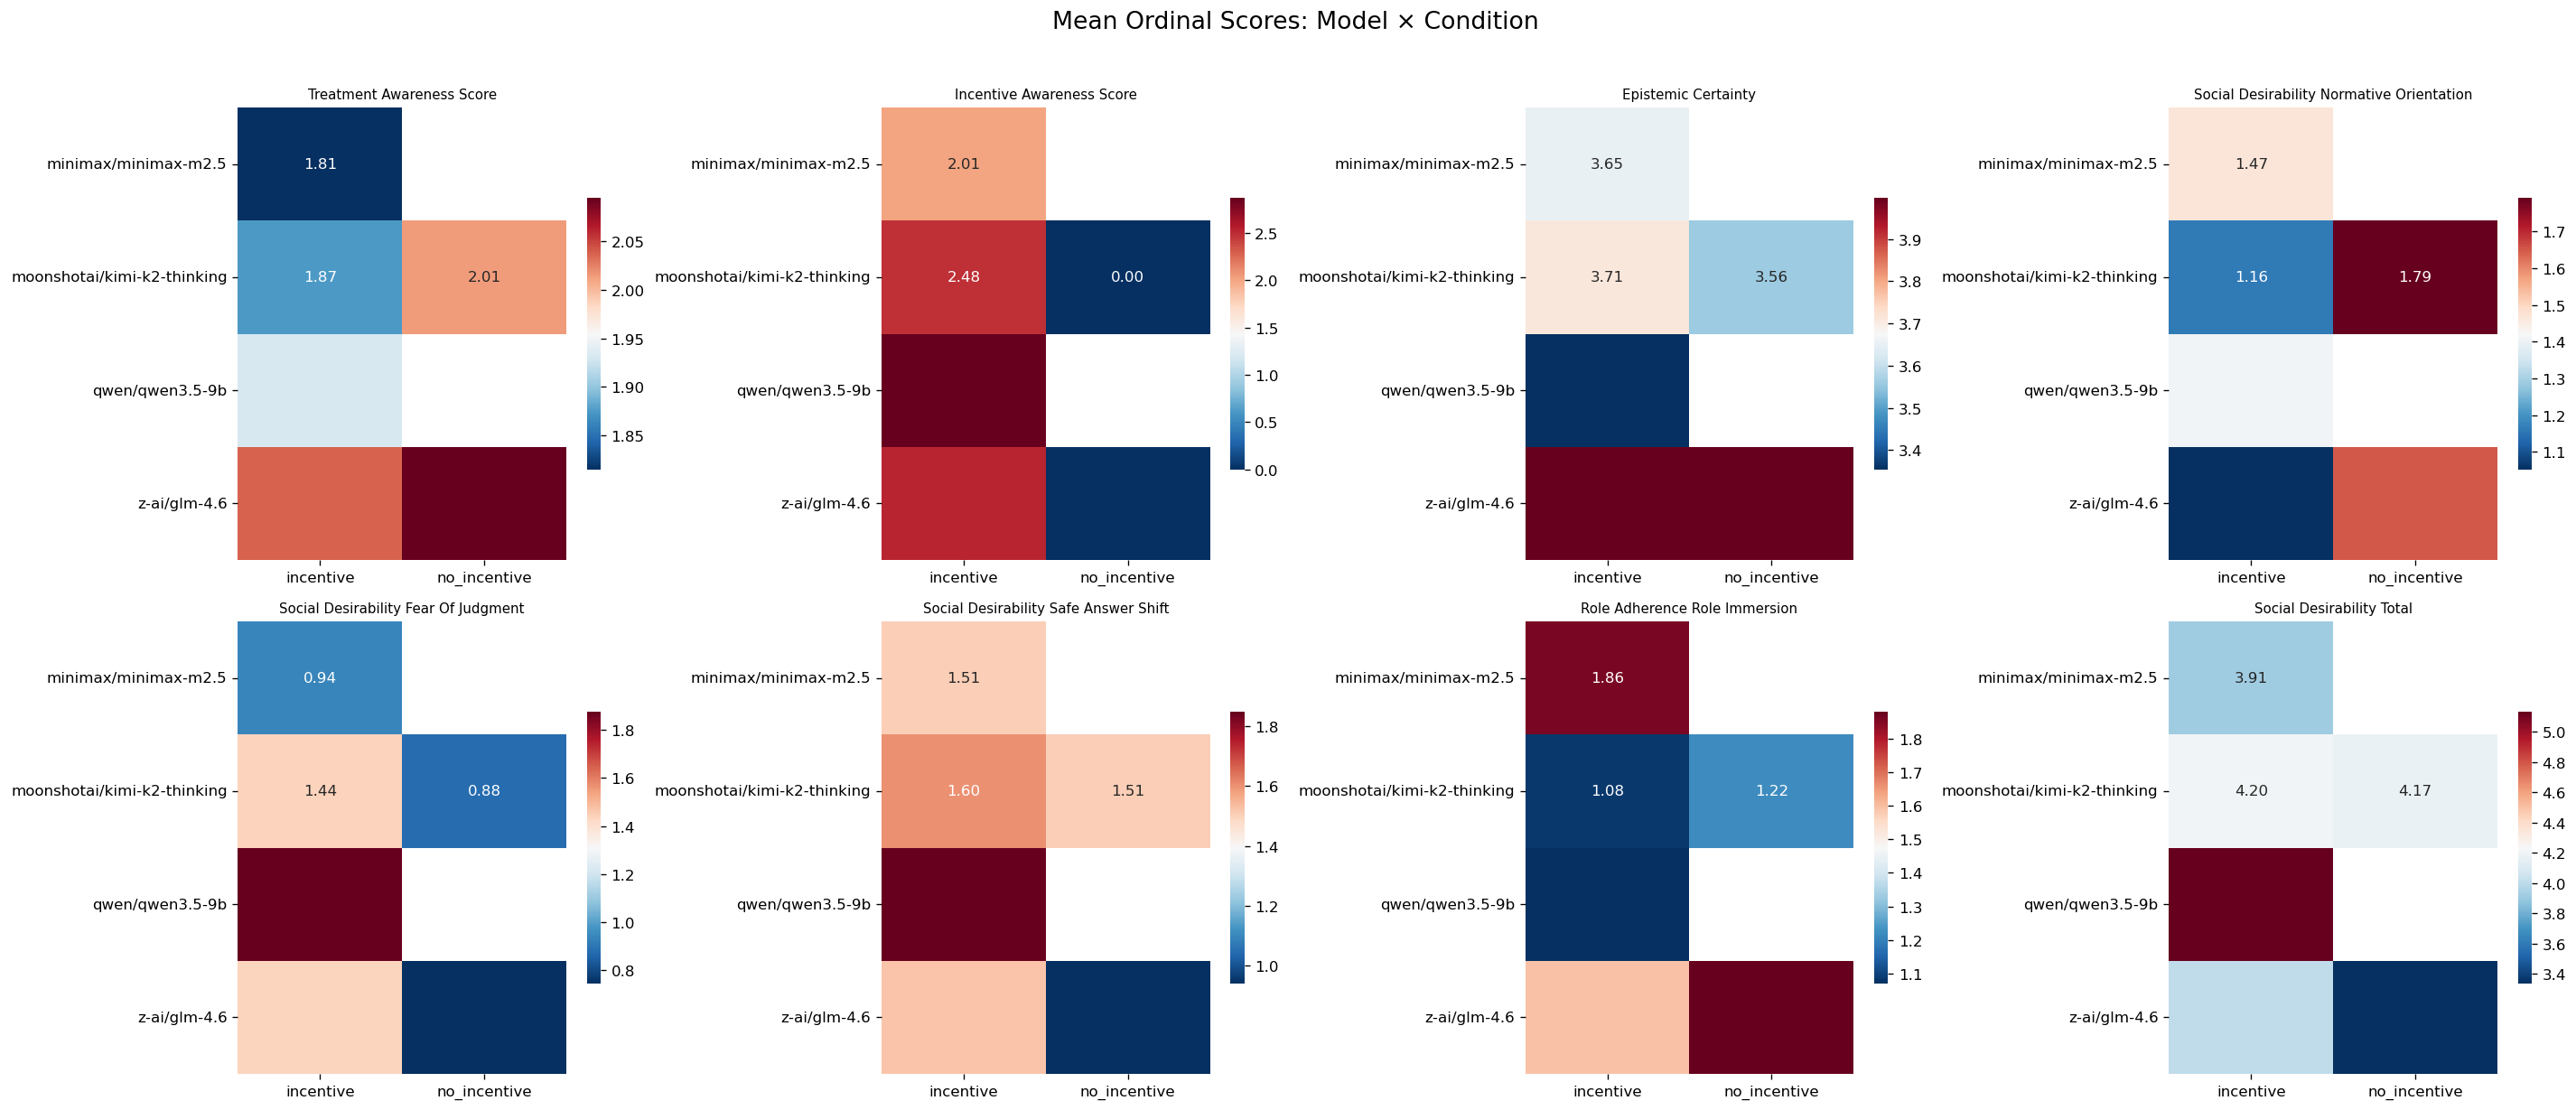

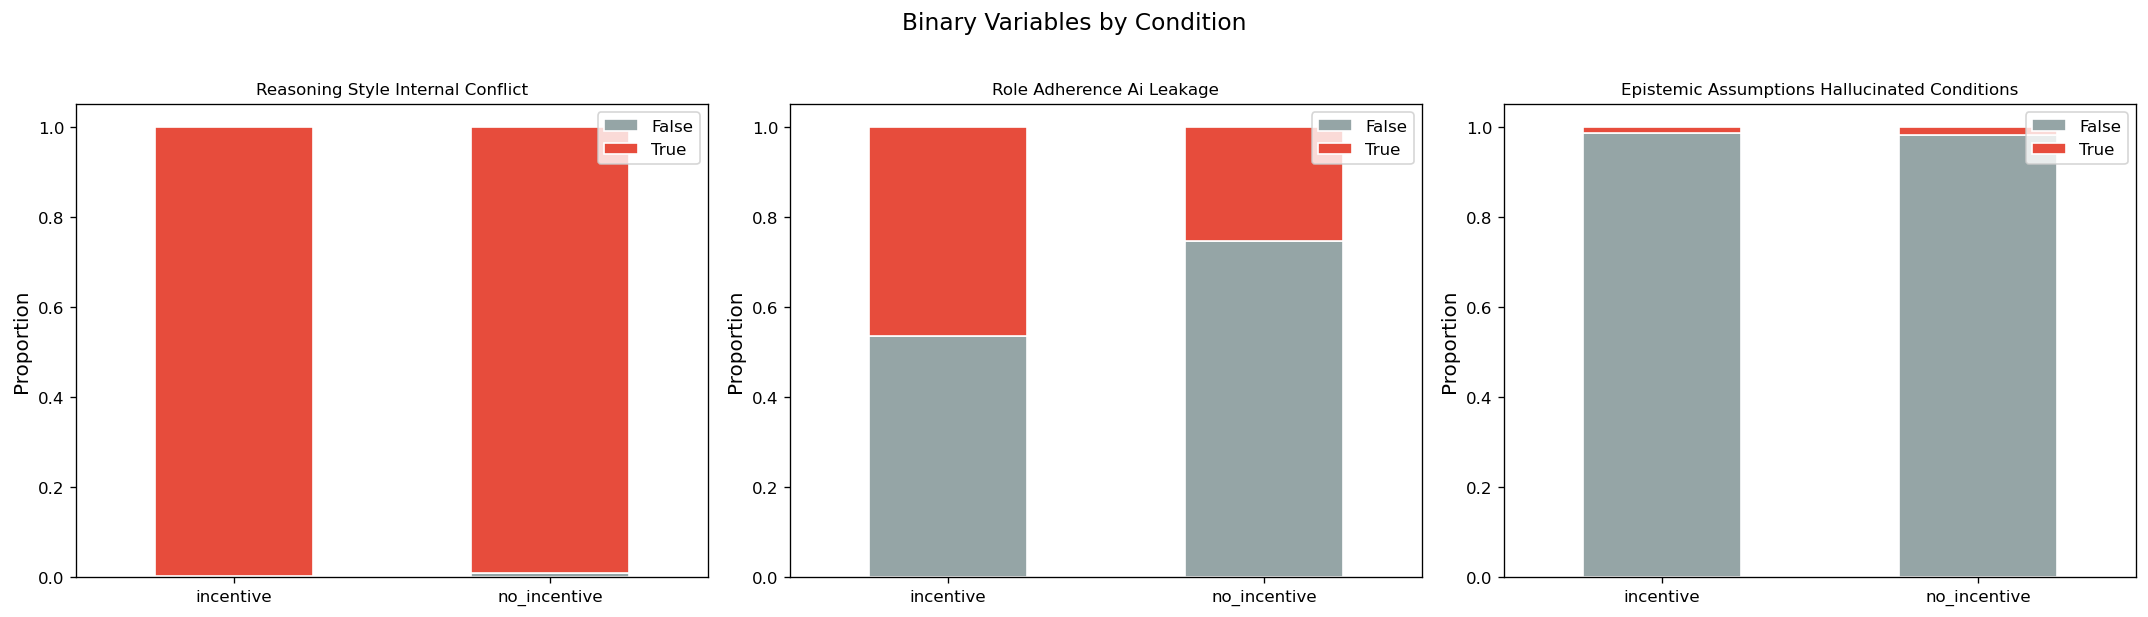

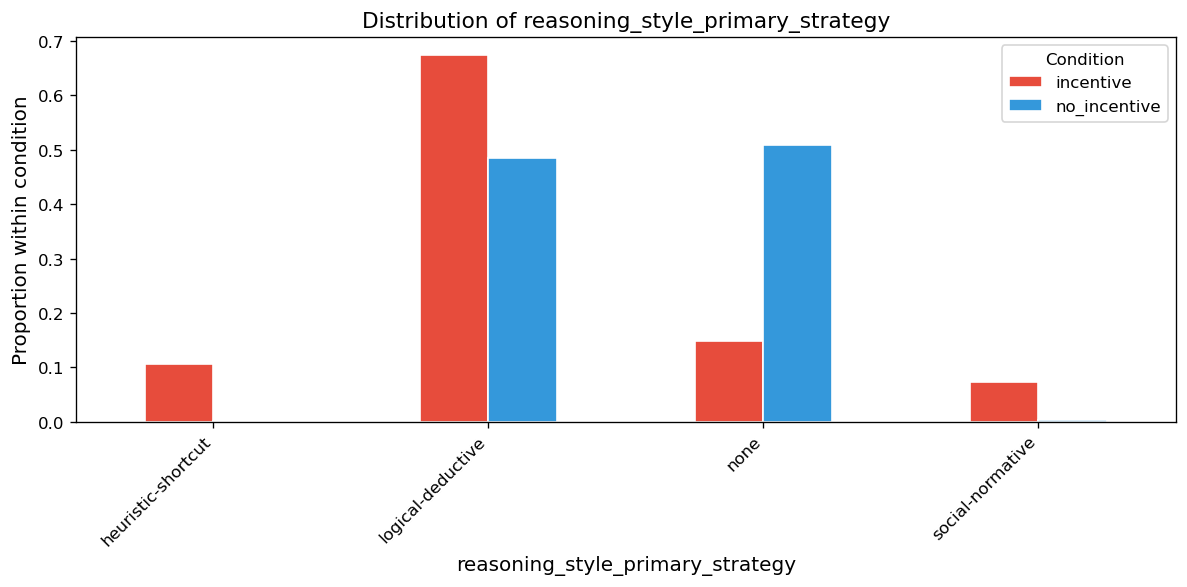

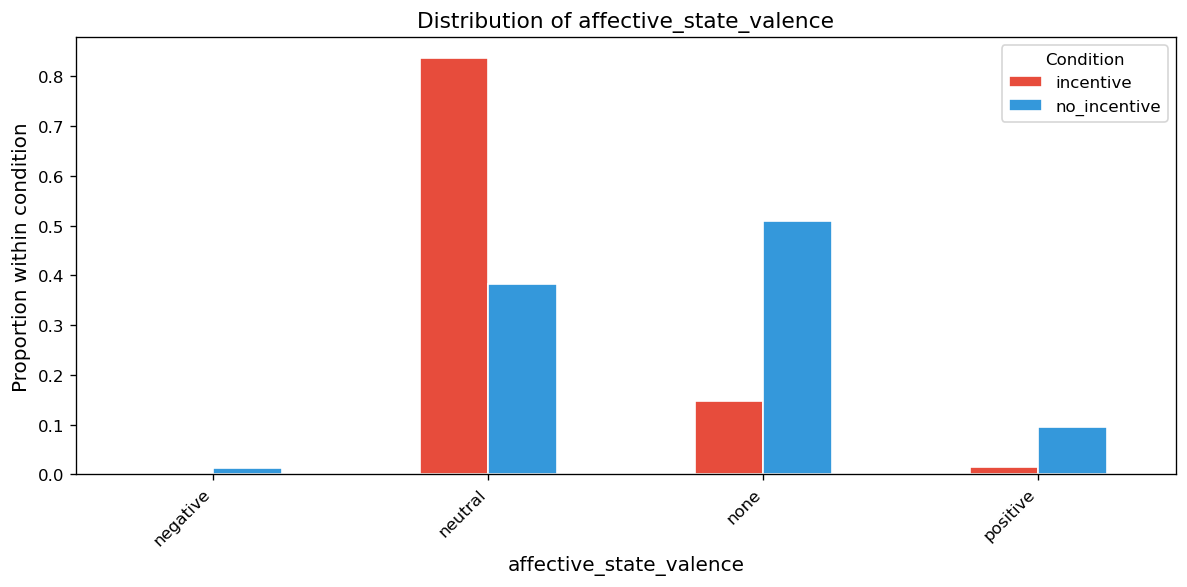

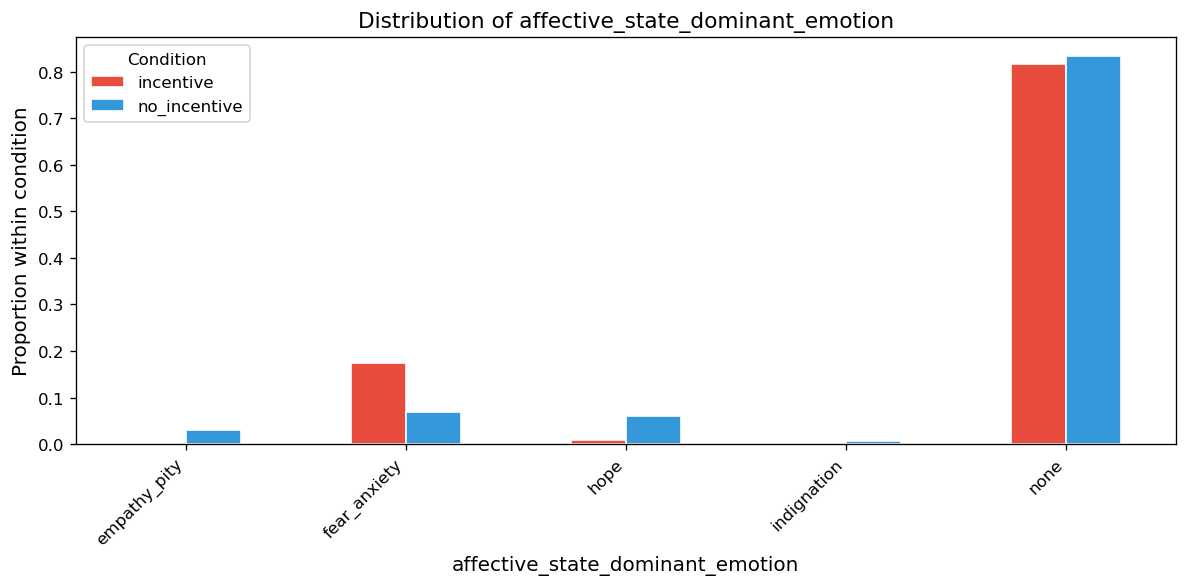

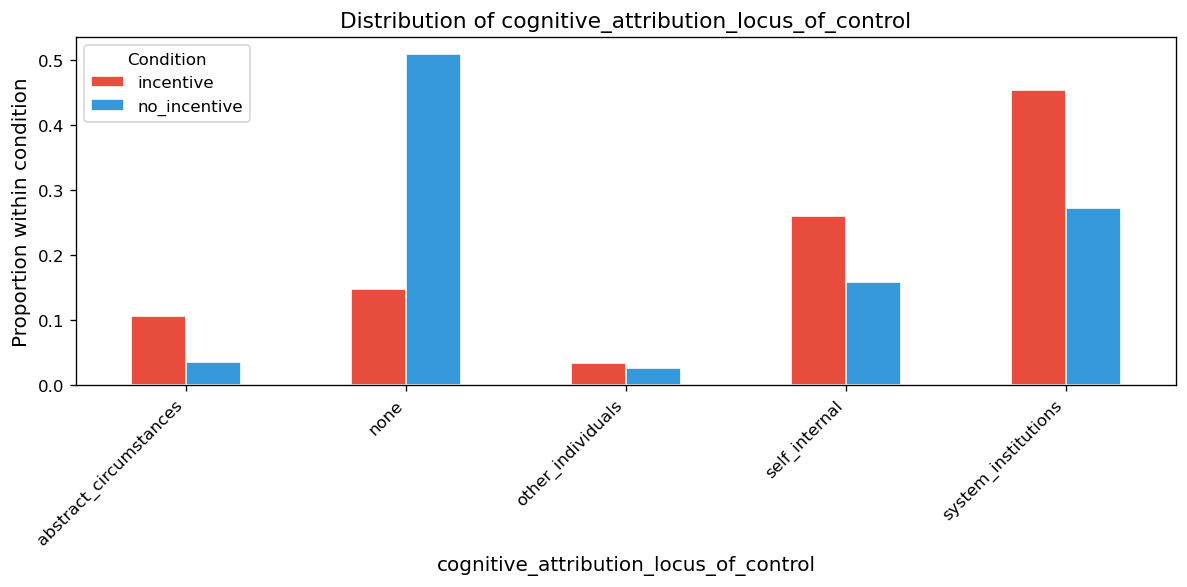

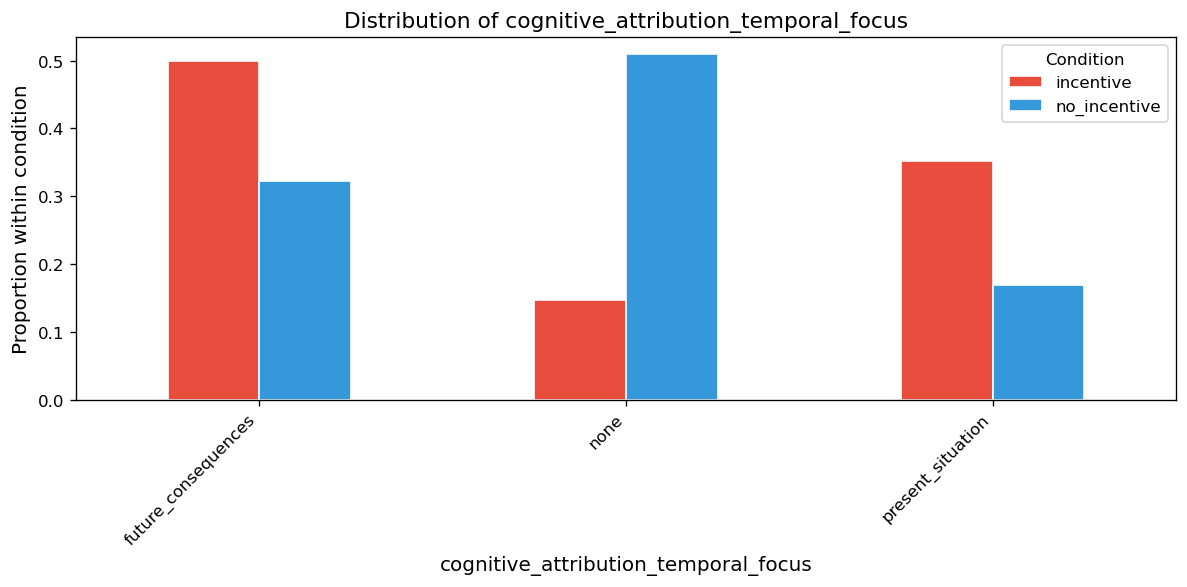

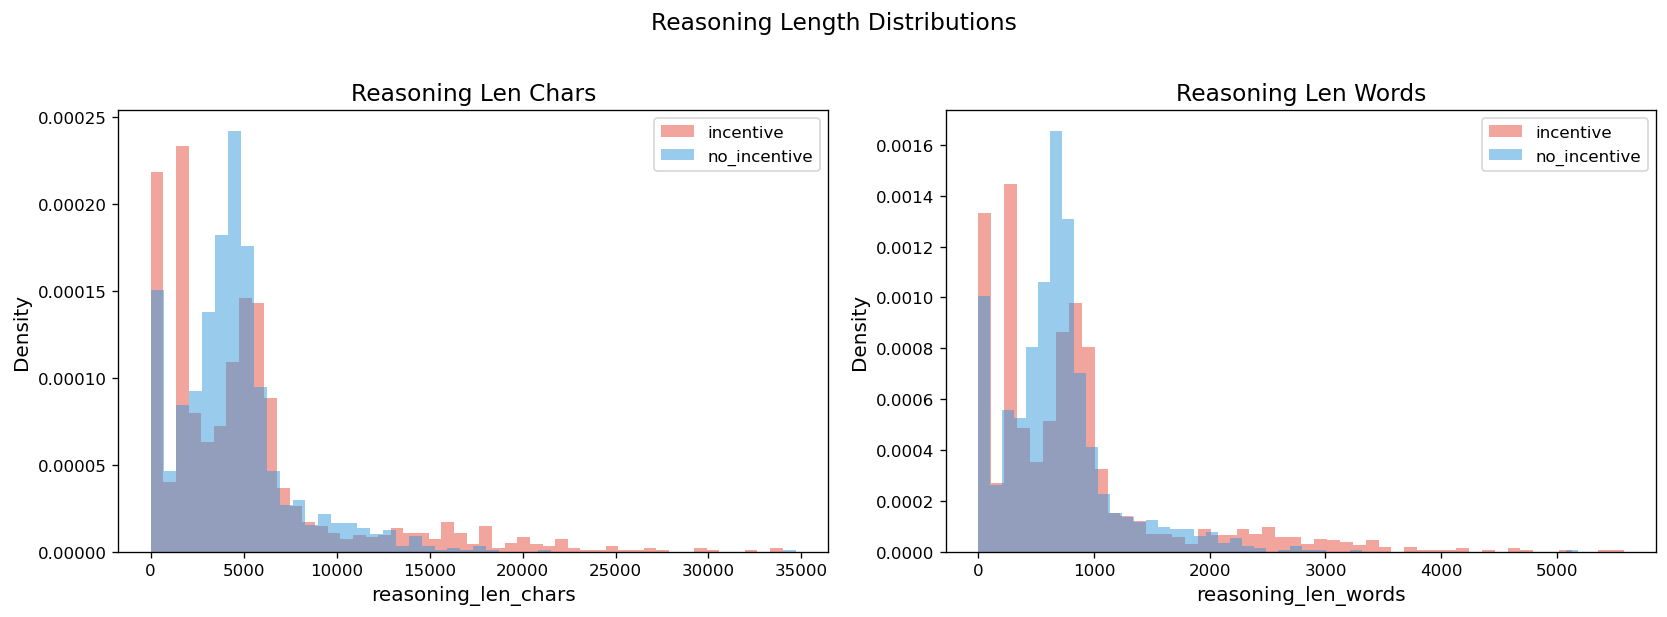


5. STATISTICAL TESTS: INCENTIVE vs NO-INCENTIVE

--- Mann-Whitney U tests (ordinal) ---
  treatment_awareness_score                           U=      373564  p=0.000412 ***  r=+0.088  mean_inc=1.911  mean_no=2.054
  incentive_awareness_score                           U=      815126  p=0.000000 ***  r=-0.989  mean_inc=2.406  mean_no=0.000
  epistemic_certainty                                 U=      388898  p=0.010713 *    r=+0.051  mean_inc=3.734  mean_no=3.774
  social_desirability_normative_orientation           U=      215951  p=0.000000 ***  r=+0.473  mean_inc=1.249  mean_no=1.722
  social_desirability_fear_of_judgment                U=      595548  p=0.000000 ***  r=-0.453  mean_inc=1.344  mean_no=0.812
  social_desirability_safe_answer_shift               U=      524516  p=0.000000 ***  r=-0.280  mean_inc=1.580  mean_no=1.229
  role_adherence_role_immersion                       U=      374922  p=0.000381 ***  r=+0.085  mean_inc=1.459  mean_no=1.544
  social_desirability_total  

In [6]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, mannwhitneyu, kruskal, spearmanr
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix
from sklearn.inspection import permutation_importance
import textwrap
from itertools import combinations

# Plotting defaults
plt.rcParams.update({
    "figure.figsize": (14, 7),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.dpi": 120,
})
palette_condition = {"incentive": "#e74c3c", "no_incentive": "#3498db"}

# =============================================================================
# 1. LOAD & UNIFY DATA
# =============================================================================
print("=" * 80)
print("1. LOADING DATA")
print("=" * 80)

df_inc = pd.read_parquet(
    "responses_final_incentive_C_balanced_realism_50_reasoning_trace_markup.parquet"
)
df_no = pd.read_parquet(
    "responses_final_no_incentive_50_reasoning_trace_p2_markup.parquet"
)

# Add condition label
df_inc["condition"] = "incentive"
df_no["condition"] = "no_incentive"

df = pd.concat([df_inc, df_no], ignore_index=True)
print(f"Incentive rows   : {len(df_inc):,}")
print(f"No-incentive rows: {len(df_no):,}")
print(f"Combined rows    : {len(df):,}")
print(f"Models           : {df['model'].unique().tolist()}")
print(f"Experiments      : {df['experiment_name'].nunique()}")

# =============================================================================
# 2. DATA CLEANING & FEATURE ENGINEERING
# =============================================================================
print("\n" + "=" * 80)
print("2. DATA CLEANING & FEATURE ENGINEERING")
print("=" * 80)

# ── 2a. Определим все аналитические переменные ──
ordinal_vars = [
    "treatment_awareness_score",
    "incentive_awareness_score",
    "epistemic_certainty",
    "social_desirability_normative_orientation",
    "social_desirability_fear_of_judgment",
    "social_desirability_safe_answer_shift",
    "role_adherence_role_immersion",
]

binary_vars = [
    "reasoning_style_internal_conflict",
    "role_adherence_ai_leakage",
    "epistemic_assumptions_hallucinated_conditions",
]

categorical_vars = [
    "reasoning_style_primary_strategy",
    "affective_state_valence",
    "affective_state_dominant_emotion",
    "cognitive_attribution_locus_of_control",
    "cognitive_attribution_temporal_focus",
]

# ── 2b. Convert types ──
for col in ordinal_vars:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in binary_vars:
    # handle True/False, 'true'/'false', 1/0
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({"true": 1, "false": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0})
    )

for col in categorical_vars:
    df[col] = df[col].astype(str).str.strip().str.lower()

# ── 2c. Composite scores ──
df["social_desirability_total"] = (
    df["social_desirability_normative_orientation"]
    + df["social_desirability_fear_of_judgment"]
    + df["social_desirability_safe_answer_shift"]
)

# ── 2d. Quick missing-value report ──
all_analysis_vars = ordinal_vars + binary_vars + categorical_vars + ["social_desirability_total"]
print("\nMissing values in analysis variables:")
print(df[all_analysis_vars].isnull().sum().to_string())

# ── 2e. Reasoning length features ──
df["reasoning_len_chars"] = df["REASONING"].astype(str).apply(len)
df["reasoning_len_words"] = df["REASONING"].astype(str).apply(lambda x: len(x.split()))

print(f"\nFinal dataframe shape: {df.shape}")

# =============================================================================
# 3. DESCRIPTIVE STATISTICS
# =============================================================================
print("\n" + "=" * 80)
print("3. DESCRIPTIVE STATISTICS")
print("=" * 80)

# ── 3a. Condition-level summary for ordinal + binary ──
desc_vars = ordinal_vars + binary_vars + ["social_desirability_total",
                                           "reasoning_len_chars", "reasoning_len_words"]

desc_by_cond = df.groupby("condition")[desc_vars].agg(["mean", "std", "median", "count"])
print("\n--- Descriptive stats by CONDITION ---")
print(desc_by_cond.round(3).to_string())

# ── 3b. Condition × Model ──
desc_by_cond_model = (
    df.groupby(["condition", "model"])[desc_vars]
    .agg(["mean", "std", "count"])
)
print("\n--- Descriptive stats by CONDITION × MODEL ---")
print(desc_by_cond_model.round(3).to_string())

# ── 3c. Frequency tables for categorical vars ──
for col in categorical_vars:
    print(f"\n--- {col} frequencies ---")
    ct = pd.crosstab(df["condition"], df[col], margins=True, normalize="index")
    print(ct.round(3).to_string())


# =============================================================================
# 4. VISUALIZATION: OVERVIEW DASHBOARDS
# =============================================================================
print("\n" + "=" * 80)
print("4. GENERATING VISUALIZATIONS")
print("=" * 80)

# ── 4a. Ordinal variables: violin + box by condition ──
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()
plot_vars = ordinal_vars + ["social_desirability_total"]
for i, var in enumerate(plot_vars):
    ax = axes[i]
    sns.violinplot(
        data=df, x="condition", y=var, palette=palette_condition,
        inner="box", cut=0, ax=ax
    )
    ax.set_title(var.replace("_", " ").title(), fontsize=10)
    ax.set_xlabel("")
for j in range(len(plot_vars), len(axes)):
    axes[j].set_visible(False)
fig.suptitle("Ordinal Variables by Condition (Violin + Box)", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("fig_01_ordinal_violin_by_condition.png", bbox_inches="tight")
plt.show()

# ── 4b. Ordinal by condition × model (heatmap of means) ──
fig, axes = plt.subplots(2, 4, figsize=(24, 10))
axes = axes.flatten()
for i, var in enumerate(plot_vars):
    ax = axes[i]
    pivot = df.pivot_table(values=var, index="model", columns="condition", aggfunc="mean")
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="RdBu_r", ax=ax, cbar_kws={"shrink": 0.6})
    ax.set_title(var.replace("_", " ").title(), fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
for j in range(len(plot_vars), len(axes)):
    axes[j].set_visible(False)
fig.suptitle("Mean Ordinal Scores: Model × Condition", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("fig_02_ordinal_heatmap_model_condition.png", bbox_inches="tight")
plt.show()

# ── 4c. Binary variables: stacked bars ──
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, var in enumerate(binary_vars):
    ax = axes[i]
    ct = pd.crosstab(df["condition"], df[var], normalize="index")
    ct.plot(kind="bar", stacked=True, ax=ax, color=["#95a5a6", "#e74c3c"], edgecolor="white")
    ax.set_title(var.replace("_", " ").title(), fontsize=10)
    ax.set_ylabel("Proportion")
    ax.set_xlabel("")
    ax.legend(["False", "True"], loc="upper right")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.suptitle("Binary Variables by Condition", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("fig_03_binary_stacked_bars.png", bbox_inches="tight")
plt.show()

# ── 4d. Categorical: grouped bar plots ──
for col in categorical_vars:
    ct = pd.crosstab(df[col], df["condition"], normalize="columns")
    fig, ax = plt.subplots(figsize=(10, 5))
    ct.plot(kind="bar", ax=ax, color=[palette_condition["incentive"],
                                       palette_condition["no_incentive"]],
            edgecolor="white")
    ax.set_title(f"Distribution of {col}", fontsize=13)
    ax.set_ylabel("Proportion within condition")
    ax.set_xlabel(col)
    ax.legend(title="Condition")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    fname = f"fig_04_categorical_{col}.png"
    plt.savefig(fname, bbox_inches="tight")
    plt.show()

# ── 4e. Reasoning length distributions ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, lvar in enumerate(["reasoning_len_chars", "reasoning_len_words"]):
    ax = axes[i]
    for cond, color in palette_condition.items():
        subset = df[df["condition"] == cond][lvar].dropna()
        ax.hist(subset, bins=50, alpha=0.5, label=cond, color=color, density=True)
    ax.set_title(lvar.replace("_", " ").title())
    ax.set_xlabel(lvar)
    ax.set_ylabel("Density")
    ax.legend()
plt.suptitle("Reasoning Length Distributions", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("fig_05_reasoning_length.png", bbox_inches="tight")
plt.show()


# =============================================================================
# 5. STATISTICAL TESTS: CONDITION EFFECT (INCENTIVE vs NO-INCENTIVE)
# =============================================================================
print("\n" + "=" * 80)
print("5. STATISTICAL TESTS: INCENTIVE vs NO-INCENTIVE")
print("=" * 80)

results_tests = []

# ── 5a. Mann-Whitney U for ordinal vars ──
print("\n--- Mann-Whitney U tests (ordinal) ---")
for var in ordinal_vars + ["social_desirability_total", "reasoning_len_words"]:
    g1 = df.loc[df["condition"] == "incentive", var].dropna()
    g2 = df.loc[df["condition"] == "no_incentive", var].dropna()
    stat, p = mannwhitneyu(g1, g2, alternative="two-sided")
    # Effect size: rank-biserial r
    n1, n2 = len(g1), len(g2)
    r_effect = 1 - (2 * stat) / (n1 * n2)
    results_tests.append({
        "variable": var, "test": "Mann-Whitney U",
        "stat": stat, "p_value": p, "effect_size_r": r_effect,
        "n_inc": n1, "n_no": n2,
        "mean_inc": g1.mean(), "mean_no": g2.mean()
    })
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
    print(f"  {var:50s}  U={stat:12.0f}  p={p:.6f} {sig:3s}  r={r_effect:+.3f}  "
          f"mean_inc={g1.mean():.3f}  mean_no={g2.mean():.3f}")

# ── 5b. Chi-squared for binary vars ──
print("\n--- Chi-squared tests (binary) ---")
for var in binary_vars:
    ct = pd.crosstab(df["condition"], df[var].fillna(-1))
    if -1 in ct.columns:
        ct = ct.drop(columns=[-1])
    if ct.shape[1] < 2:
        print(f"  {var}: skipped (no variance)")
        continue
    chi2, p, dof, expected = chi2_contingency(ct)
    # Cramér's V
    n = ct.sum().sum()
    k = min(ct.shape)
    cramers_v = np.sqrt(chi2 / (n * (k - 1))) if (n * (k - 1)) > 0 else 0
    results_tests.append({
        "variable": var, "test": "Chi-squared",
        "stat": chi2, "p_value": p, "effect_size_r": cramers_v,
        "n_inc": len(df[df["condition"] == "incentive"]),
        "n_no": len(df[df["condition"] == "no_incentive"]),
        "mean_inc": df.loc[df["condition"] == "incentive", var].mean(),
        "mean_no": df.loc[df["condition"] == "no_incentive", var].mean()
    })
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
    print(f"  {var:50s}  χ²={chi2:10.3f}  p={p:.6f} {sig:3s}  V={cramers_v:.3f}  "
          f"prop_inc={df.loc[df['condition']=='incentive', var].mean():.3f}  "
          f"prop_no={df.loc[df['condition']=='no_incentive', var].mean():.3f}")

# ── 5c. Chi-squared for categorical vars ──
print("\n--- Chi-squared tests (categorical) ---")
for var in categorical_vars:
    ct = pd.crosstab(df["condition"], df[var])
    chi2, p, dof, expected = chi2_contingency(ct)
    n = ct.sum().sum()
    k = min(ct.shape)
    cramers_v = np.sqrt(chi2 / (n * (k - 1))) if (n * (k - 1)) > 0 else 0
    results_tests.append({
        "variable": var, "test": "Chi-squared",
        "stat": chi2, "p_value": p, "effect_size_r": cramers_v,
        "n_inc": len(df[df["condition"] == "incentive"]),
        "n_no": len(df[df["condition"] == "no_incentive"]),
        "mean_inc": np.nan, "mean_no": np.nan
    })
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
    print(f"  {var:50s}  χ²={chi2:10.3f}  p={p:.6f} {sig:3s}  V={cramers_v:.3f}")

# ── 5d. Multiple testing correction ──
df_tests = pd.DataFrame(results_tests)
reject, p_adj, _, _ = multipletests(df_tests["p_value"], method="fdr_bh")
df_tests["p_adjusted_fdr"] = p_adj
df_tests["significant_fdr05"] = reject

print("\n--- All tests with FDR correction ---")
print(df_tests.to_string(index=False))
df_tests.to_csv("statistical_tests_summary.csv", index=False)


6. WITHIN-MODEL ANALYSIS

────────────────────────────────────────────────────────────
Model: moonshotai/kimi-k2-thinking (n=700)
────────────────────────────────────────────────────────────
  treatment_awareness_score                     p=0.0174 *   r=+0.095  mean_inc=1.874  mean_no=2.014
  incentive_awareness_score                     p=0.0000 *** r=-1.000  mean_inc=2.483  mean_no=0.000
  epistemic_certainty                           p=0.0040 **  r=-0.102  mean_inc=3.711  mean_no=3.560
  social_desirability_normative_orientation     p=0.0000 *** r=+0.631  mean_inc=1.160  mean_no=1.791
  social_desirability_fear_of_judgment          p=0.0000 *** r=-0.505  mean_inc=1.440  mean_no=0.877
  social_desirability_safe_answer_shift         p=0.0145 *   r=-0.092  mean_inc=1.603  mean_no=1.506
  role_adherence_role_immersion                 p=0.0000 *** r=+0.137  mean_inc=1.083  mean_no=1.220
  social_desirability_total                     p=0.9775     r=+0.001  mean_inc=4.203  mean_no=4.174


  role_adherence_role_immersion                 p=0.0000 *** r=+0.287  mean_inc=1.593  mean_no=1.881
  social_desirability_total                     p=0.0000 *** r=-0.261  mean_inc=4.009  mean_no=3.335
  reasoning_len_words                           p=0.0000 *** r=-0.310  mean_inc=836.409  mean_no=776.866

────────────────────────────────────────────────────────────
Model: qwen/qwen3.5-9b (n=700)
────────────────────────────────────────────────────────────
  reasoning_len_words                           p=0.2759     r=-0.044  mean_inc=1128.054  mean_no=558.809

────────────────────────────────────────────────────────────
Model: minimax/minimax-m2.5 (n=700)
────────────────────────────────────────────────────────────
  reasoning_len_words                           p=0.0000 *** r=+0.436  mean_inc=304.280  mean_no=478.537

--- Within-model tests saved to within_model_tests.csv ---


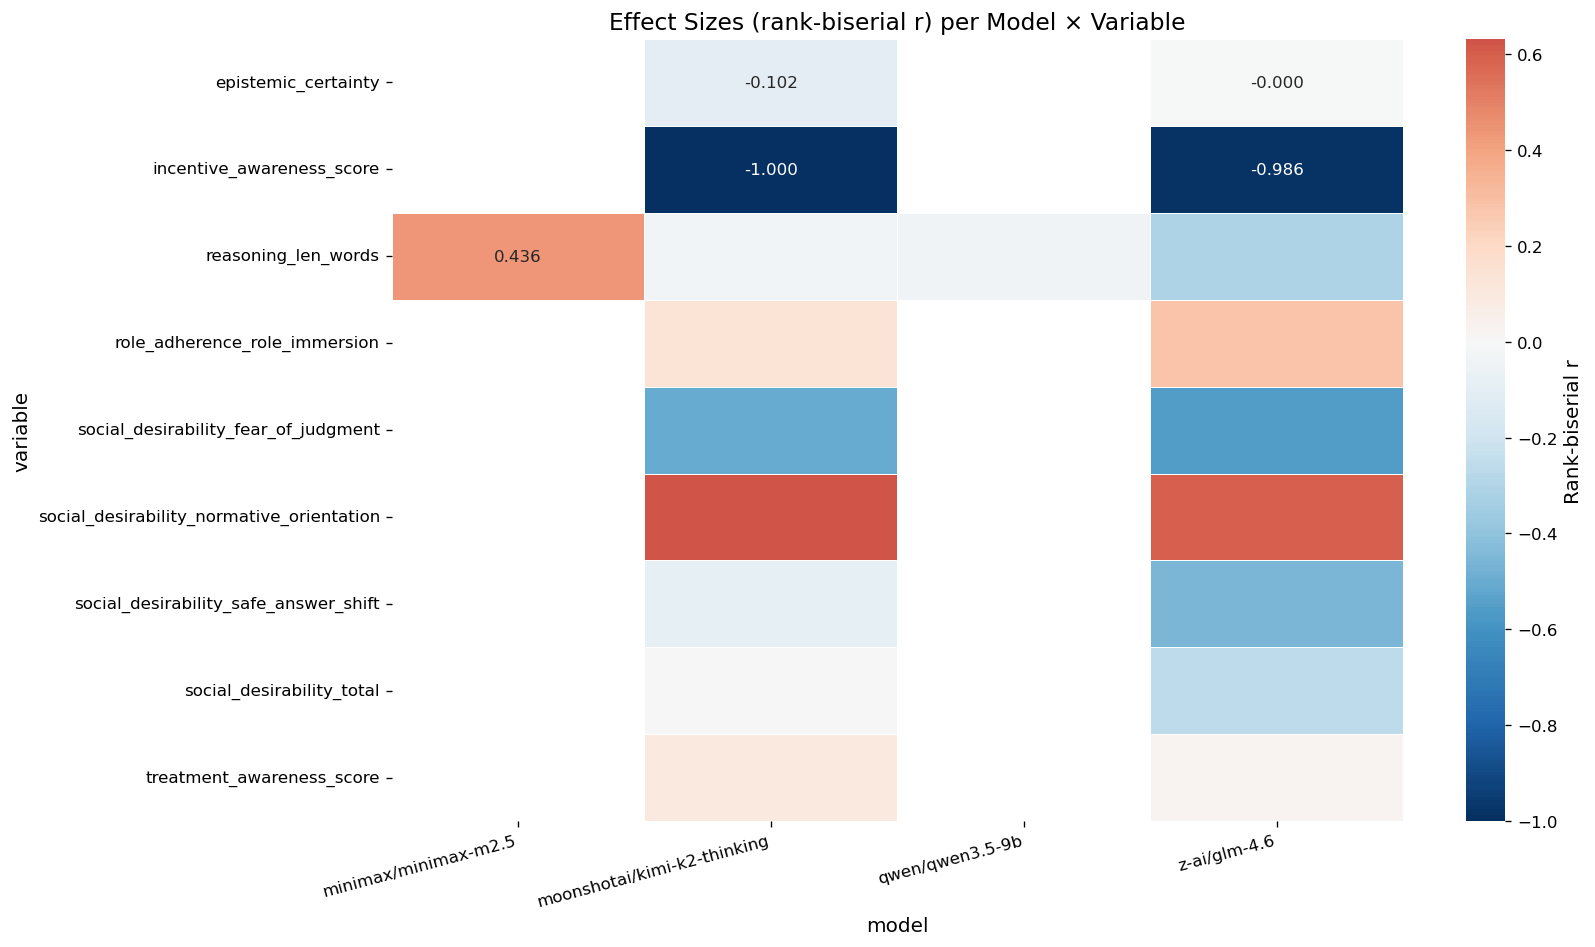

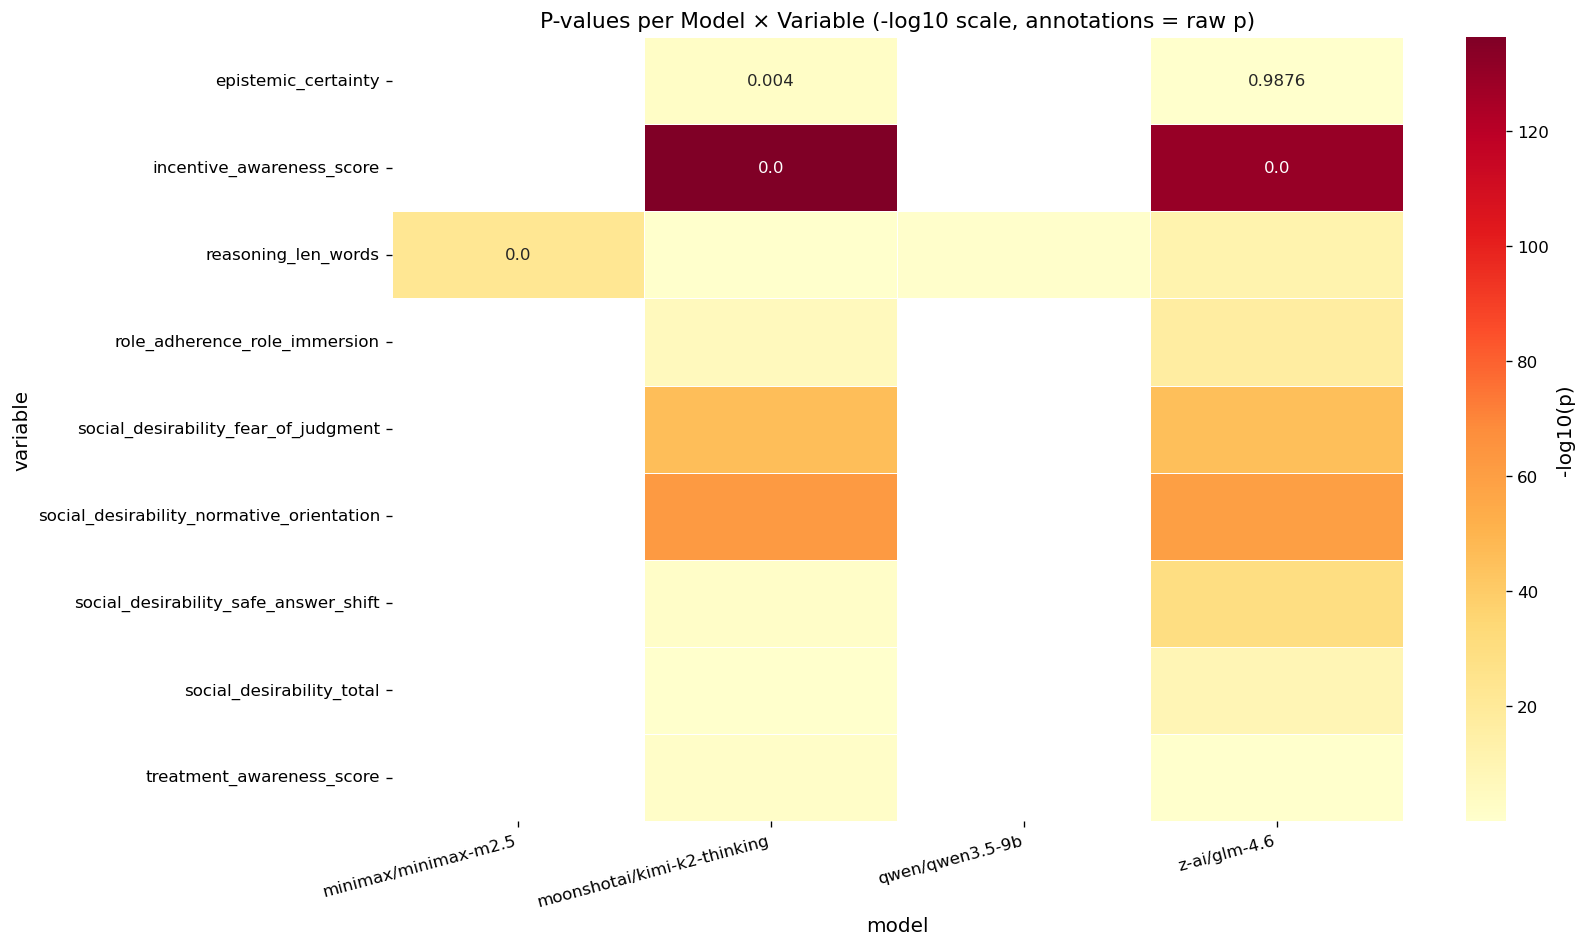

In [7]:
print("\n" + "=" * 80)
print("6. WITHIN-MODEL ANALYSIS")
print("=" * 80)

models = df["model"].unique()
within_model_results = []

for model_name in models:
    dfm = df[df["model"] == model_name]
    print(f"\n{'─'*60}")
    print(f"Model: {model_name} (n={len(dfm)})")
    print(f"{'─'*60}")
    for var in ordinal_vars + ["social_desirability_total", "reasoning_len_words"]:
        g1 = dfm.loc[dfm["condition"] == "incentive", var].dropna()
        g2 = dfm.loc[dfm["condition"] == "no_incentive", var].dropna()
        if len(g1) < 5 or len(g2) < 5:
            continue
        stat, p = mannwhitneyu(g1, g2, alternative="two-sided")
        n1, n2 = len(g1), len(g2)
        r_effect = 1 - (2 * stat) / (n1 * n2)
        within_model_results.append({
            "model": model_name, "variable": var,
            "stat": stat, "p_value": p, "effect_size_r": r_effect,
            "mean_inc": g1.mean(), "mean_no": g2.mean()
        })
        sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
        print(f"  {var:45s} p={p:.4f} {sig:3s} r={r_effect:+.3f}  "f"mean_inc={g1.mean():.3f}  mean_no={g2.mean():.3f}")

df_within = pd.DataFrame(within_model_results)
if len(df_within) > 0:
    reject_w, p_adj_w, _, _ = multipletests(df_within["p_value"], method="fdr_bh")
    df_within["p_adjusted_fdr"] = p_adj_w
    df_within["significant_fdr05"] = reject_w
    df_within.to_csv("within_model_tests.csv", index=False)
    print("\n--- Within-model tests saved to within_model_tests.csv ---")

# ── 6b. Heatmap: effect sizes within each model ──
if len(df_within) > 0:
    pivot_eff = df_within.pivot_table(
        values="effect_size_r", index="variable", columns="model"
    )
    fig, ax = plt.subplots(figsize=(14, 8))
    sns.heatmap(
        pivot_eff, annot=True, fmt=".3f", cmap="RdBu_r", center=0,
        ax=ax, linewidths=0.5, cbar_kws={"label": "Rank-biserial r"}
    )
    ax.set_title("Effect Sizes (rank-biserial r) per Model × Variable", fontsize=14)
    plt.xticks(rotation=15, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig("fig_06_effect_sizes_heatmap_by_model.png", bbox_inches="tight")
    plt.show()

    # ── 6c. Heatmap: p-values within each model ──
    pivot_p = df_within.pivot_table(
        values="p_value", index="variable", columns="model"
    )
    fig, ax = plt.subplots(figsize=(14, 8))
    sns.heatmap(
        -np.log10(pivot_p + 1e-300), annot=pivot_p.round(4).values,
        fmt="", cmap="YlOrRd", ax=ax, linewidths=0.5,
        cbar_kws={"label": "-log10(p)"}
    )
    ax.set_title("P-values per Model × Variable (-log10 scale, annotations = raw p)", fontsize=13)
    plt.xticks(rotation=15, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig("fig_06b_pvalues_heatmap_by_model.png", bbox_inches="tight")
    plt.show
              

In [8]:
print("\n" + "=" * 80)
print("7. WITHIN-EXPERIMENT ANALYSIS")
print("=" * 80)

experiments = df["experiment_name"].unique()
within_exp_results = []

for exp_name in experiments:
    dfe = df[df["experiment_name"] == exp_name]
    for var in ordinal_vars + ["social_desirability_total"]:
        g1 = dfe.loc[dfe["condition"] == "incentive", var].dropna()
        g2 = dfe.loc[dfe["condition"] == "no_incentive", var].dropna()
        if len(g1) < 3 or len(g2) < 3:
            continue
        stat, p = mannwhitneyu(g1, g2, alternative="two-sided")
        n1, n2 = len(g1), len(g2)
        r_effect = 1 - (2 * stat) / (n1 * n2)
        within_exp_results.append({
            "experiment": exp_name, "variable": var,
            "stat": stat, "p_value": p, "effect_size_r": r_effect,
            "mean_inc": g1.mean(), "mean_no": g2.mean(),
            "n_inc": n1, "n_no": n2
        })

df_within_exp = pd.DataFrame(within_exp_results)
if len(df_within_exp) > 0:
    reject_e, p_adj_e, _, _ = multipletests(df_within_exp["p_value"], method="fdr_bh")
    df_within_exp["p_adjusted_fdr"] = p_adj_e
    df_within_exp["significant_fdr05"] = reject_e
    df_within_exp.to_csv("within_experiment_tests.csv", index=False)

    # Top significant experiment-level effects
    sig_exp = df_within_exp[df_within_exp["significant_fdr05"]].sort_values("p_adjusted_fdr")
    print(f"\nSignificant experiment-level effects (FDR < 0.05): {len(sig_exp)}")
    if len(sig_exp) > 0:
        print(sig_exp[["experiment", "variable", "effect_size_r",
                        "p_value", "p_adjusted_fdr", "mean_inc", "mean_no"]].head(30).to_string(index=False))


7. WITHIN-EXPERIMENT ANALYSIS

Significant experiment-level effects (FDR < 0.05): 13
                                                     experiment                                  variable  effect_size_r       p_value  p_adjusted_fdr  mean_inc  mean_no
  Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture                 incentive_awareness_score      -0.998514 1.804000e-185   2.886400e-184  2.414562 0.000000
Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate                 incentive_awareness_score      -0.976923 2.636219e-130   2.108975e-129  2.394231 0.000000
Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate social_desirability_normative_orientation       0.705736  2.073415e-96    1.105821e-95  1.053846 1.759582
  Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture      social_desirability_fear_of_judgment      -0.528232  5.572093e-68    2.228837e-67  1.445765 0.850000
Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate 

In [9]:
print("\n" + "=" * 80)
print("8. CORRELATION ANALYSIS")
print("=" * 80)

numeric_features = (
    ordinal_vars + binary_vars +
    ["social_desirability_total", "reasoning_len_words"]
)

# ── 8a. Overall Spearman correlation matrix ──
corr_data = df[numeric_features].dropna()
corr_matrix, p_matrix = pd.DataFrame(
    np.zeros((len(numeric_features), len(numeric_features))),
    index=numeric_features, columns=numeric_features
), pd.DataFrame(
    np.zeros((len(numeric_features), len(numeric_features))),
    index=numeric_features, columns=numeric_features
)

for c1 in numeric_features:
    for c2 in numeric_features:
        valid = corr_data[[c1, c2]].dropna()
        if len(valid) > 3:
            rho, p = spearmanr(valid[c1], valid[c2])
            corr_matrix.loc[c1, c2] = rho
            p_matrix.loc[c1, c2] = p
        else:
            corr_matrix.loc[c1, c2] = np.nan
            p_matrix.loc[c1, c2] = np.nan

fig, ax = plt.subplots(figsize=(16, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
    center=0, ax=ax, linewidths=0.5, square=True,
    cbar_kws={"label": "Spearman ρ"}
)
ax.set_title("Spearman Correlation Matrix (all data)", fontsize=14)
plt.tight_layout()
plt.savefig("fig_07_correlation_matrix.png", bbox_inches="tight")
plt.show()

# ── 8b. Correlations SPLIT by condition ──
for cond in ["incentive", "no_incentive"]:
    subset = df[df["condition"] == cond][numeric_features].dropna()
    corr_cond = subset.corr(method="spearman")
    fig, ax = plt.subplots(figsize=(14, 10))
    mask_c = np.triu(np.ones_like(corr_cond, dtype=bool), k=1)
    sns.heatmap(
        corr_cond, mask=mask_c, annot=True, fmt=".2f", cmap="RdBu_r",
        center=0, ax=ax, linewidths=0.5, square=True
    )
    ax.set_title(f"Spearman Correlations — {cond}", fontsize=13)
    plt.tight_layout()
    plt.savefig(f"fig_08_correlation_{cond}.png", bbox_inches="tight")
    plt.show()




8. CORRELATION ANALYSIS


ValueError: setting an array element with a sequence.


9. LOGISTIC REGRESSION: Predicting Condition
Features: 31
Samples : 1880 (dropped 920 with NaN)
Class balance: {1: 1193, 0: 687}
Statsmodels logit failed: Singular matrix



Logistic Regression CV AUC: 0.9997 ± 0.0006
  C= 0.001  AUC=0.5000±0.0000  non-zero=0
  C= 0.010  AUC=0.9946±0.0028  non-zero=1


  C= 0.050  AUC=0.9987±0.0009  non-zero=6


  C= 0.100  AUC=0.9996±0.0007  non-zero=8


  C= 0.500  AUC=0.9997±0.0006  non-zero=11


  C= 1.000  AUC=0.9997±0.0005  non-zero=12


  C= 5.000  AUC=0.9996±0.0005  non-zero=17


  C=10.000  AUC=0.9995±0.0006  non-zero=19


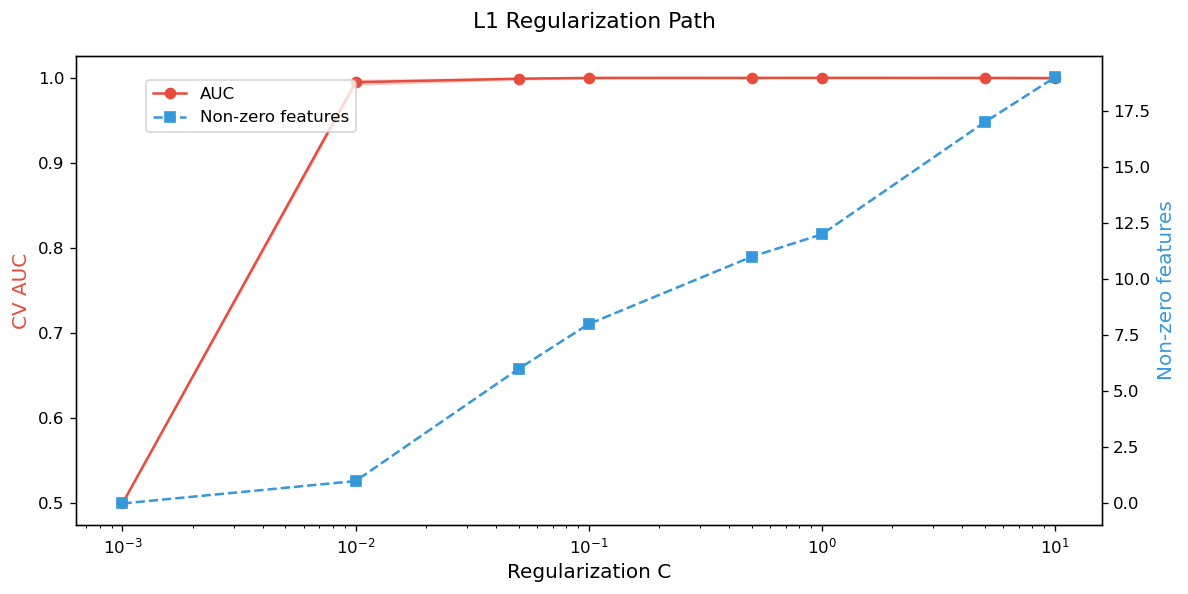

In [10]:
print("\n" + "=" * 80)
print("9. LOGISTIC REGRESSION: Predicting Condition")
print("=" * 80)

# ── 9a. Prepare feature matrix ──
# Encode categorical vars
df_model = df.copy()
df_model["condition_bin"] = (df_model["condition"] == "incentive").astype(int)

# One-hot encode categorical
cat_dummies = pd.get_dummies(
    df_model[categorical_vars], prefix=categorical_vars, drop_first=True, dtype=int
)

# Combine features
feature_cols_numeric = [
    c for c in (ordinal_vars + binary_vars + ["social_desirability_total"])
    if c not in {"reasoning_len_words", "reasoning_len_chars"}
]
X_numeric = df_model[feature_cols_numeric].copy()
X_all = pd.concat([X_numeric, cat_dummies], axis=1)

# Add model dummies (control for model)
model_dummies = pd.get_dummies(df_model["model"], prefix="model", drop_first=True, dtype=int)
X_all = pd.concat([X_all, model_dummies], axis=1)

y = df_model["condition_bin"]

# Drop rows with NaN
valid_mask = X_all.notna().all(axis=1) & y.notna()
X_clean = X_all[valid_mask].reset_index(drop=True)
y_clean = y[valid_mask].reset_index(drop=True)

print(f"Features: {X_clean.shape[1]}")
print(f"Samples : {X_clean.shape[0]} (dropped {len(df) - len(X_clean)} with NaN)")
print(f"Class balance: {y_clean.value_counts().to_dict()}")

# ── 9b. Statsmodels logistic regression (for coefficients + p-values) ──
X_sm = sm.add_constant(X_clean.astype(float))
try:
    logit_model = sm.Logit(y_clean, X_sm).fit(disp=0, maxiter=200)
    print("\n--- Statsmodels Logistic Regression Summary ---")
    print(logit_model.summary2())

    # Extract coefficients
    coef_df = pd.DataFrame({
        "coef": logit_model.params,
        "std_err": logit_model.bse,
        "z": logit_model.tvalues,
        "p_value": logit_model.pvalues,
        "odds_ratio": np.exp(logit_model.params),
        "ci_lower": np.exp(logit_model.conf_int()[0]),
        "ci_upper": np.exp(logit_model.conf_int()[1]),
    })
    coef_df = coef_df.sort_values("p_value")
    coef_df.to_csv("logistic_regression_coefficients.csv")
    print("\nTop 20 coefficients by significance:")
    print(coef_df.head(20).to_string())

    # ── 9c. Odds Ratio forest plot ──
    coef_plot = coef_df.drop("const", errors="ignore").head(20).copy()
    coef_plot = coef_plot.sort_values("odds_ratio")

    fig, ax = plt.subplots(figsize=(10, 8))
    y_pos = range(len(coef_plot))
    ax.errorbar(
        coef_plot["odds_ratio"], y_pos,
        xerr=[
            coef_plot["odds_ratio"] - coef_plot["ci_lower"],
            coef_plot["ci_upper"] - coef_plot["odds_ratio"]
        ],
        fmt="o", color="#2c3e50", ecolor="#95a5a6", capsize=3, markersize=5
    )
    ax.axvline(x=1, color="red", linestyle="--", alpha=0.7)
    ax.set_yticks(y_pos)
    ax.set_yticklabels([textwrap.fill(str(idx), 40) for idx in coef_plot.index])
    ax.set_xlabel("Odds Ratio (95% CI)")
    ax.set_title("Logistic Regression: Top 20 Predictors of Incentive Condition", fontsize=13)
    plt.tight_layout()
    plt.savefig("fig_09_odds_ratio_forest.png", bbox_inches="tight")
    plt.show()

except Exception as e:
    print(f"Statsmodels logit failed: {e}")

# ── 9d. Sklearn Logistic Regression with cross-validation ──
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean.astype(float))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr = LogisticRegression(max_iter=1000, C=1.0, penalty="l2", random_state=42)
scores_lr = cross_val_score(lr, X_scaled, y_clean, cv=cv, scoring="roc_auc")
print(f"\nLogistic Regression CV AUC: {scores_lr.mean():.4f} ± {scores_lr.std():.4f}")

# ── 9e. Regularization path (L1) — feature selection ──
lr_l1 = LogisticRegression(max_iter=1000, penalty="l1", solver="saga", random_state=42)
C_values = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0]
l1_results = []

for C in C_values:
    lr_l1.set_params(C=C)
    sc = cross_val_score(lr_l1, X_scaled, y_clean, cv=cv, scoring="roc_auc")
    n_nonzero = None
    lr_l1.fit(X_scaled, y_clean)
    n_nonzero = np.sum(lr_l1.coef_[0] != 0)
    l1_results.append({"C": C, "AUC_mean": sc.mean(), "AUC_std": sc.std(),
                        "n_nonzero_features": n_nonzero})
    print(f"  C={C:6.3f}  AUC={sc.mean():.4f}±{sc.std():.4f}  non-zero={n_nonzero}")

df_l1 = pd.DataFrame(l1_results)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(df_l1["C"], df_l1["AUC_mean"], "o-", color="#e74c3c", label="AUC")
ax1.fill_between(
    df_l1["C"],
    df_l1["AUC_mean"] - df_l1["AUC_std"],
    df_l1["AUC_mean"] + df_l1["AUC_std"],
    alpha=0.2, color="#e74c3c"
)
ax1.set_xlabel("Regularization C")
ax1.set_ylabel("CV AUC", color="#e74c3c")
ax1.set_xscale("log")
ax2 = ax1.twinx()
ax2.plot(df_l1["C"], df_l1["n_nonzero_features"], "s--", color="#3498db", label="Non-zero features")
ax2.set_ylabel("Non-zero features", color="#3498db")
fig.suptitle("L1 Regularization Path", fontsize=13)
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
plt.tight_layout()
plt.savefig("fig_10_l1_regularization_path.png", bbox_inches="tight")
plt.show()




10. TREE-BASED MODELS


Random Forest CV AUC: 0.9993 ± 0.0009



Top 15 features (permutation importance):
                                               feature  importance_mdi  importance_perm_mean  importance_perm_std
                  social_desirability_fear_of_judgment        0.101684              0.222195             0.009496
                      affective_state_valence_positive        0.011906              0.001003             0.000253
                                   reasoning_len_words        0.066290              0.000728             0.000471
                             social_desirability_total        0.029427              0.000490             0.000182
                 reasoning_style_primary_strategy_none        0.000000              0.000325             0.000113
                                 model_qwen/qwen3.5-9b        0.011129              0.000117             0.000119
         affective_state_dominant_emotion_fear_anxiety        0.003670              0.000099             0.000034
                                   epistemic_

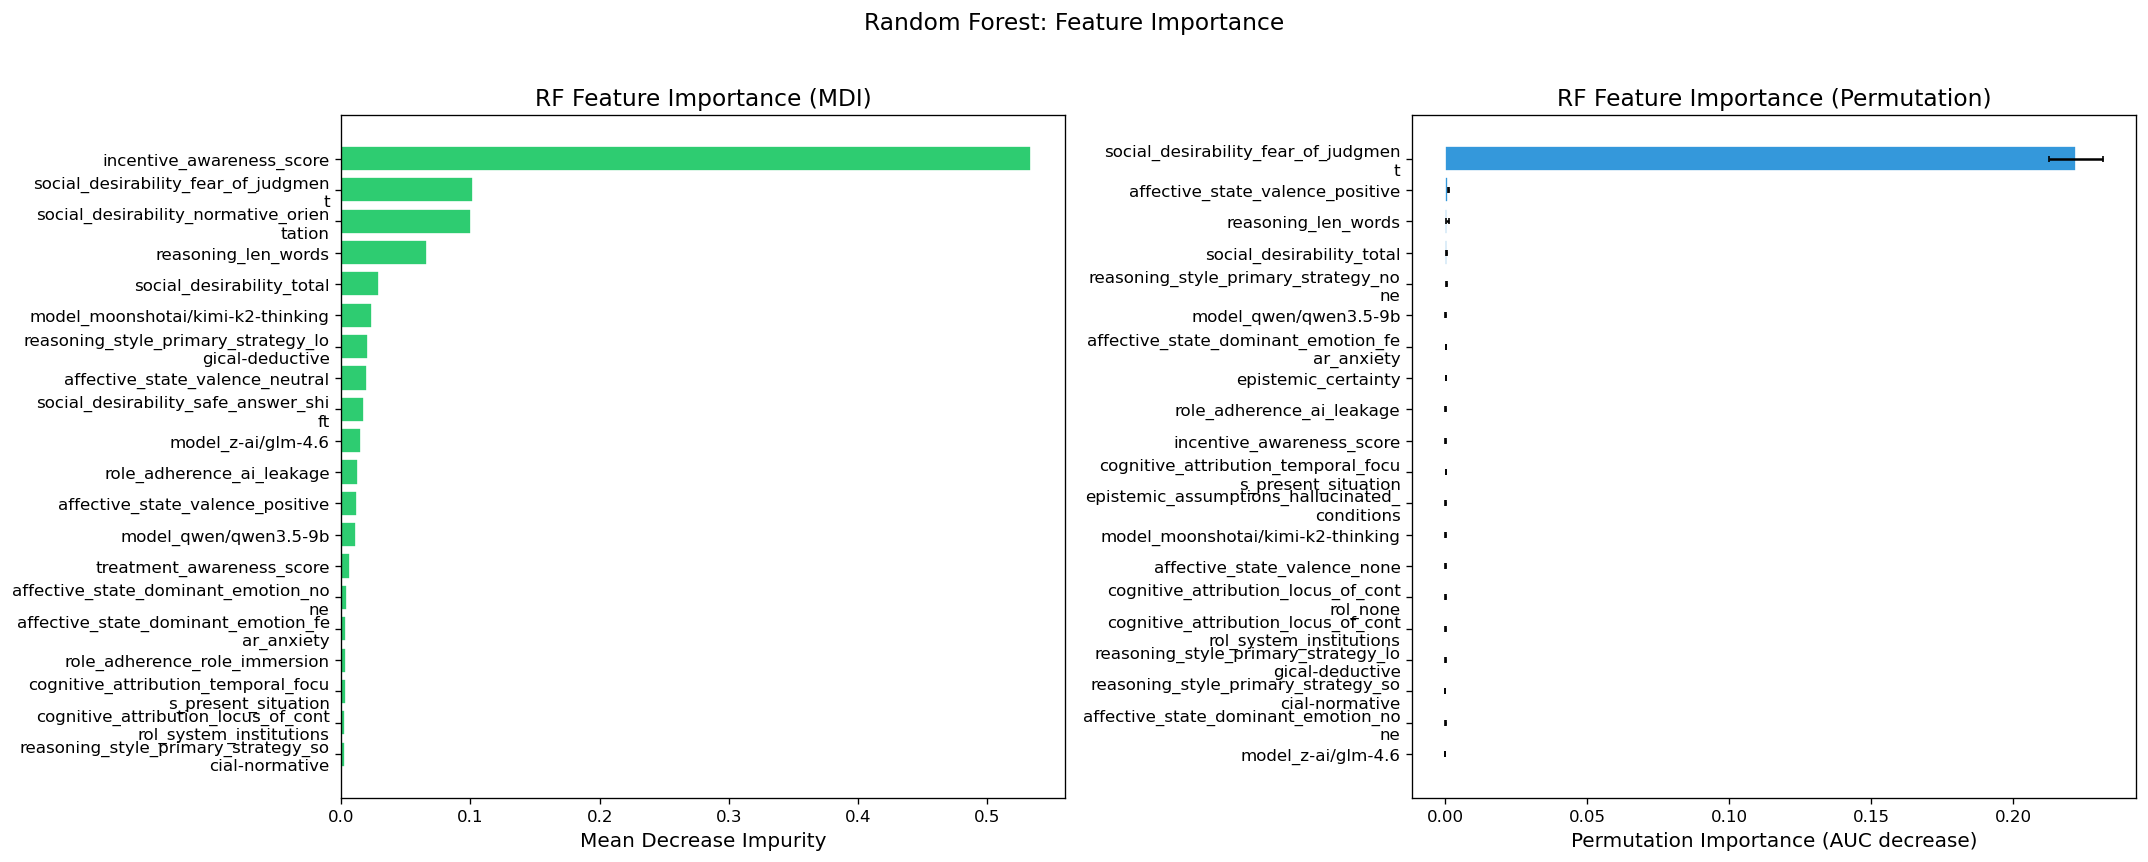


Gradient Boosting CV AUC: 0.9992 ± 0.0010



Top 15 features (Gradient Boosting):
                                               feature  importance_gb
                             incentive_awareness_score       0.975060
                                   reasoning_len_words       0.018216
  cognitive_attribution_locus_of_control_self_internal       0.001400
                             treatment_awareness_score       0.001350
             social_desirability_normative_orientation       0.001304
                     model_moonshotai/kimi-k2-thinking       0.001082
                             role_adherence_ai_leakage       0.000565
                 affective_state_dominant_emotion_none       0.000478
                         role_adherence_role_immersion       0.000105
                                    model_z-ai/glm-4.6       0.000092
                  social_desirability_fear_of_judgment       0.000090
cognitive_attribution_temporal_focus_present_situation       0.000083
                      affective_state_valence_positi

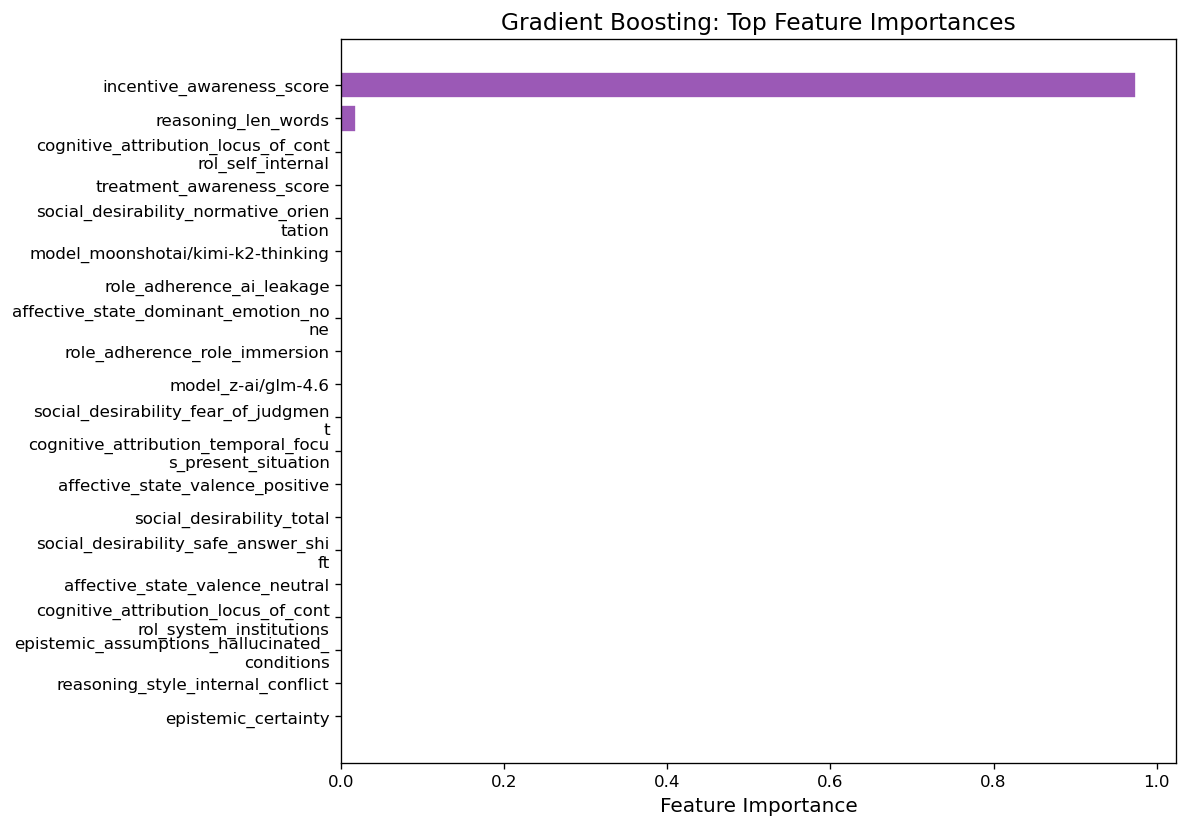


--- Model Comparison ---
                   Model  CV_AUC_mean  CV_AUC_std
Logistic Regression (L2)     0.999652    0.000637
           Random Forest     0.999347    0.000924
       Gradient Boosting     0.999185    0.001024


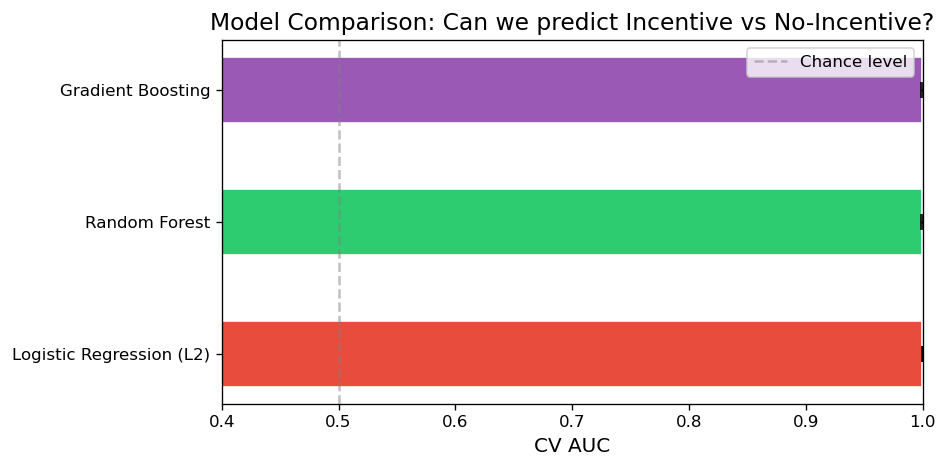

In [11]:
print("\n" + "=" * 80)
print("10. TREE-BASED MODELS")
print("=" * 80)

# ── 10a. Random Forest ──
rf = RandomForestClassifier(n_estimators=500, max_depth=8, min_samples_leaf=10,
                             random_state=42, n_jobs=-1, class_weight="balanced")
scores_rf = cross_val_score(rf, X_scaled, y_clean, cv=cv, scoring="roc_auc")
print(f"Random Forest CV AUC: {scores_rf.mean():.4f} ± {scores_rf.std():.4f}")

rf.fit(X_scaled, y_clean)

# Feature importance (MDI)
fi_rf = pd.DataFrame({
    "feature": X_clean.columns,
    "importance_mdi": rf.feature_importances_
}).sort_values("importance_mdi", ascending=False)

# Permutation importance
perm_imp = permutation_importance(rf, X_scaled, y_clean, n_repeats=20,
                                   random_state=42, scoring="roc_auc", n_jobs=-1)
fi_rf["importance_perm_mean"] = perm_imp.importances_mean
fi_rf["importance_perm_std"] = perm_imp.importances_std
fi_rf = fi_rf.sort_values("importance_perm_mean", ascending=False)
fi_rf.to_csv("random_forest_feature_importance.csv", index=False)

print("\nTop 15 features (permutation importance):")
print(fi_rf.head(15).to_string(index=False))

# Plot
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
top_n = 20

# MDI
ax = axes[0]
top_mdi = fi_rf.sort_values("importance_mdi", ascending=True).tail(top_n)
ax.barh(range(top_n), top_mdi["importance_mdi"], color="#2ecc71", edgecolor="white")
ax.set_yticks(range(top_n))
ax.set_yticklabels([textwrap.fill(f, 35) for f in top_mdi["feature"]])
ax.set_xlabel("Mean Decrease Impurity")
ax.set_title("RF Feature Importance (MDI)")

# Permutation
ax = axes[1]
top_perm = fi_rf.sort_values("importance_perm_mean", ascending=True).tail(top_n)
ax.barh(range(top_n), top_perm["importance_perm_mean"], color="#3498db", edgecolor="white",
        xerr=top_perm["importance_perm_std"].values, capsize=2)
ax.set_yticks(range(top_n))
ax.set_yticklabels([textwrap.fill(f, 35) for f in top_perm["feature"]])
ax.set_xlabel("Permutation Importance (AUC decrease)")
ax.set_title("RF Feature Importance (Permutation)")

plt.suptitle("Random Forest: Feature Importance", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("fig_11_rf_feature_importance.png", bbox_inches="tight")
plt.show()

# ── 10b. Gradient Boosting ──
gb = GradientBoostingClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    min_samples_leaf=10, subsample=0.8, random_state=42
)
scores_gb = cross_val_score(gb, X_scaled, y_clean, cv=cv, scoring="roc_auc")
print(f"\nGradient Boosting CV AUC: {scores_gb.mean():.4f} ± {scores_gb.std():.4f}")

gb.fit(X_scaled, y_clean)

fi_gb = pd.DataFrame({
    "feature": X_clean.columns,
    "importance_gb": gb.feature_importances_
}).sort_values("importance_gb", ascending=False)
fi_gb.to_csv("gradient_boosting_feature_importance.csv", index=False)

print("\nTop 15 features (Gradient Boosting):")
print(fi_gb.head(15).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 7))
top_gb = fi_gb.sort_values("importance_gb", ascending=True).tail(top_n)
ax.barh(range(len(top_gb)), top_gb["importance_gb"], color="#9b59b6", edgecolor="white")
ax.set_yticks(range(len(top_gb)))
ax.set_yticklabels([textwrap.fill(f, 35) for f in top_gb["feature"]])
ax.set_xlabel("Feature Importance")
ax.set_title("Gradient Boosting: Top Feature Importances")
plt.tight_layout()
plt.savefig("fig_12_gb_feature_importance.png", bbox_inches="tight")
plt.show()

# ── 10c. Model comparison summary ──
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression (L2)", "Random Forest", "Gradient Boosting"],
    "CV_AUC_mean": [scores_lr.mean(), scores_rf.mean(), scores_gb.mean()],
    "CV_AUC_std": [scores_lr.std(), scores_rf.std(), scores_gb.std()],
})
print("\n--- Model Comparison ---")
print(model_comparison.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#e74c3c", "#2ecc71", "#9b59b6"]
ax.barh(model_comparison["Model"], model_comparison["CV_AUC_mean"],
        xerr=model_comparison["CV_AUC_std"], color=colors, edgecolor="white",
        capsize=5, height=0.5)
ax.set_xlabel("CV AUC")
ax.set_title("Model Comparison: Can we predict Incentive vs No-Incentive?")
ax.axvline(0.5, color="gray", linestyle="--", alpha=0.5, label="Chance level")
ax.set_xlim(0.4, 1.0)
ax.legend()
plt.tight_layout()
plt.savefig("fig_13_model_comparison.png", bbox_inches="tight")
plt.show()




11. ROC CURVES


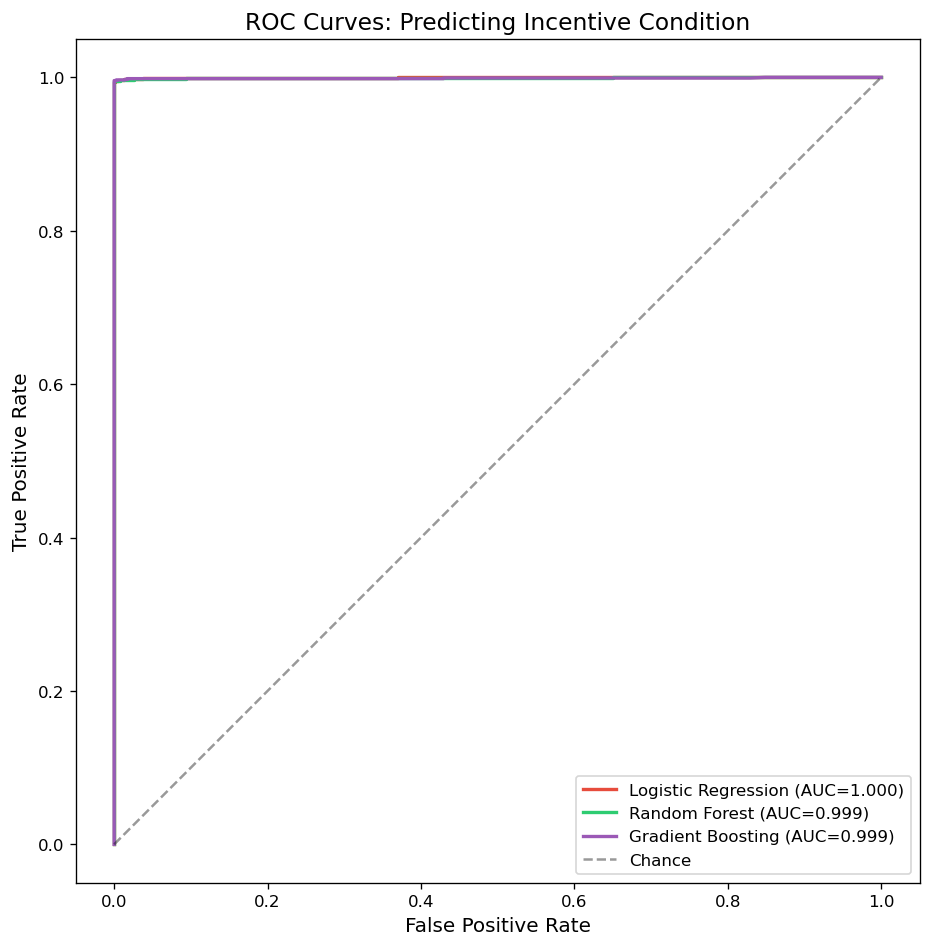

In [12]:
print("\n" + "=" * 80)
print("11. ROC CURVES")
print("=" * 80)

fig, ax = plt.subplots(figsize=(8, 8))

models_dict = {
    "Logistic Regression": LogisticRegression(max_iter=1000, C=1.0, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=500, max_depth=8,
                                             min_samples_leaf=10, random_state=42,
                                             n_jobs=-1, class_weight="balanced"),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=300, max_depth=4,
                                                     learning_rate=0.05,
                                                     min_samples_leaf=10,
                                                     subsample=0.8, random_state=42),
}

colors_roc = ["#e74c3c", "#2ecc71", "#9b59b6"]

for (name, clf), color in zip(models_dict.items(), colors_roc):
    # Use cross-validated predictions
    from sklearn.model_selection import cross_val_predict
    y_proba = cross_val_predict(clf, X_scaled, y_clean, cv=cv, method="predict_proba")[:, 1]
    fpr, tpr, _ = roc_curve(y_clean, y_proba)
    auc_val = roc_auc_score(y_clean, y_proba)
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC={auc_val:.3f})")

ax.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Chance")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves: Predicting Incentive Condition")
ax.legend(loc="lower right")
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("fig_14_roc_curves.png", bbox_inches="tight")
plt.show()



12. MIXED-EFFECTS MODELS (Condition → Outcome, controlling for model & experiment)


/opt/anaconda3/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood opti

  treatment_awareness_score                      β=-0.0996  p=0.150444  (simplified)
  incentive_awareness_score                      β=+2.5061  p=0.000000 *** (simplified)
  epistemic_certainty                            β=+0.0752  p=0.002342 ** (simplified)
  social_desirability_total                      β=+0.3490  p=0.000000 *** (simplified)


/opt/anaconda3/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood opti

  reasoning_style_internal_conflict              β=+0.0102  p=0.012573 * (simplified)
  role_adherence_ai_leakage                      β=+0.4039  p=0.000000 *** (simplified)
  role_adherence_role_immersion                  β=-0.2117  p=0.000000 *** (simplified)
  reasoning_len_words                            β=+110.5207  p=0.000004 *** (simplified)
  social_desirability_safe_answer_shift          β=+0.3376  p=0.000000 *** (simplified)

--- Mixed-effects results ---
                              outcome  coef_condition        se          z      p_value    n  converged  p_adjusted_fdr  significant_fdr05
            treatment_awareness_score       -0.099578  0.069249  -1.437966 1.504436e-01 1880      False    1.504436e-01              False
            incentive_awareness_score        2.506077  0.023851 105.071669 0.000000e+00 1880       True    0.000000e+00               True
                  epistemic_certainty        0.075182  0.024706   3.042999 2.342330e-03 1880       True    3.011

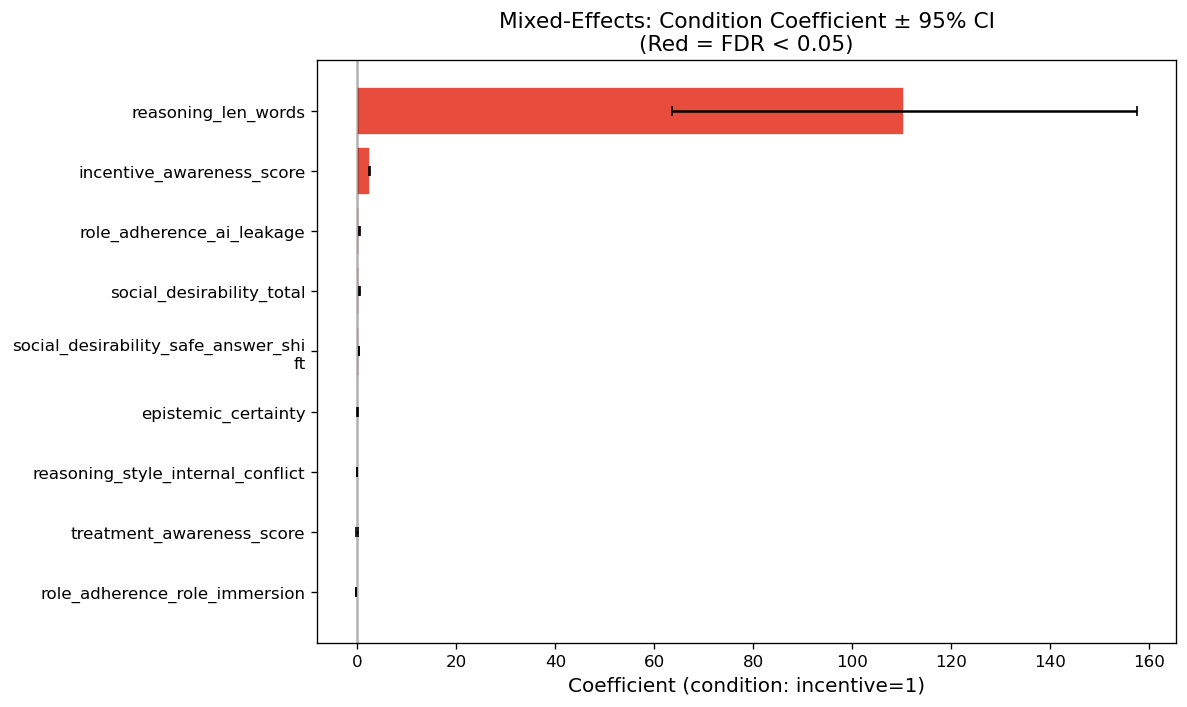


13. INTERACTION ANALYSIS: CONDITION × MODEL
  incentive_awareness_score: interaction model failed — Error evaluating factor: TypeError: 'float' object is not callable
    incentive_awareness_score ~ condition_bin * C(model)
                                                ^^^^^^^^
  social_desirability_total: interaction model failed — Error evaluating factor: TypeError: 'float' object is not callable
    social_desirability_total ~ condition_bin * C(model)
                                                ^^^^^^^^
  epistemic_certainty: interaction model failed — Error evaluating factor: TypeError: 'float' object is not callable
    epistemic_certainty ~ condition_bin * C(model)
                                          ^^^^^^^^
  treatment_awareness_score: interaction model failed — Error evaluating factor: TypeError: 'float' object is not callable
    treatment_awareness_score ~ condition_bin * C(model)
                                                ^^^^^^^^
  role_adherence_role_imm

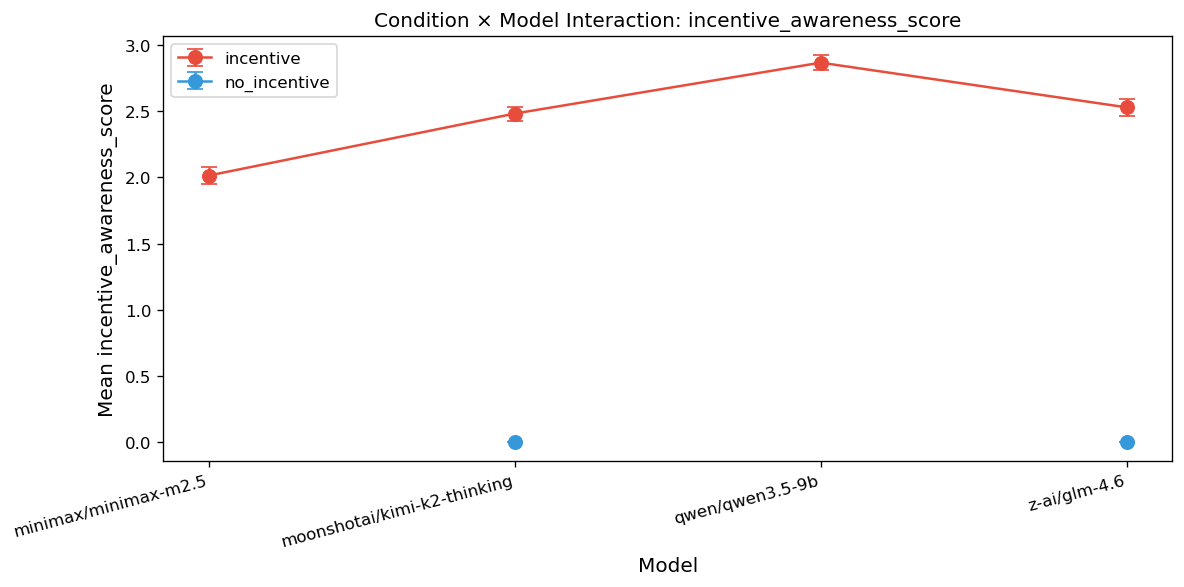

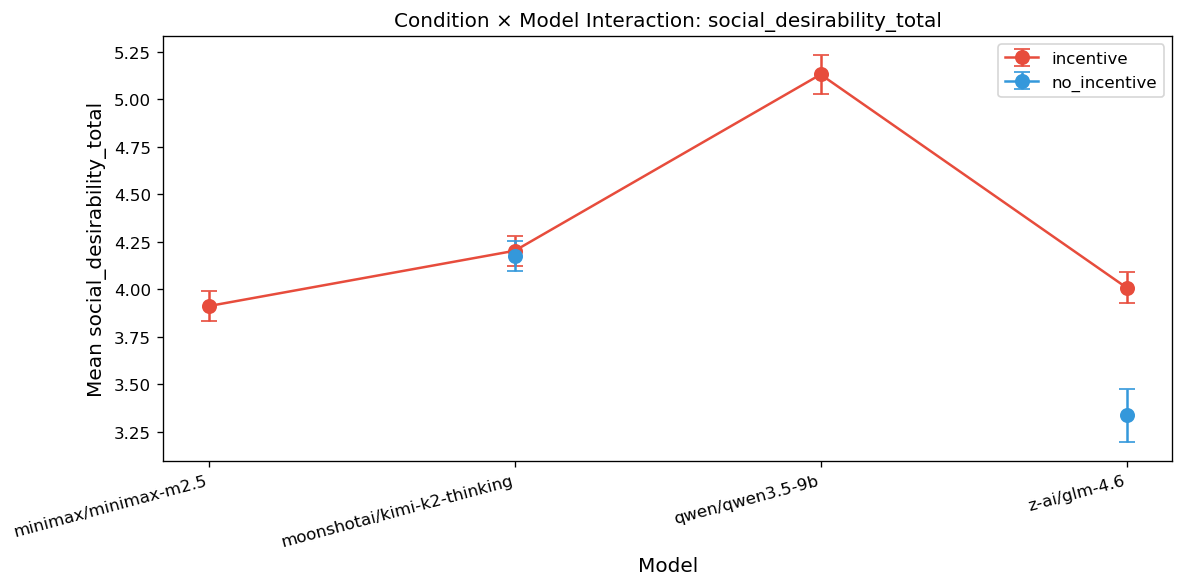

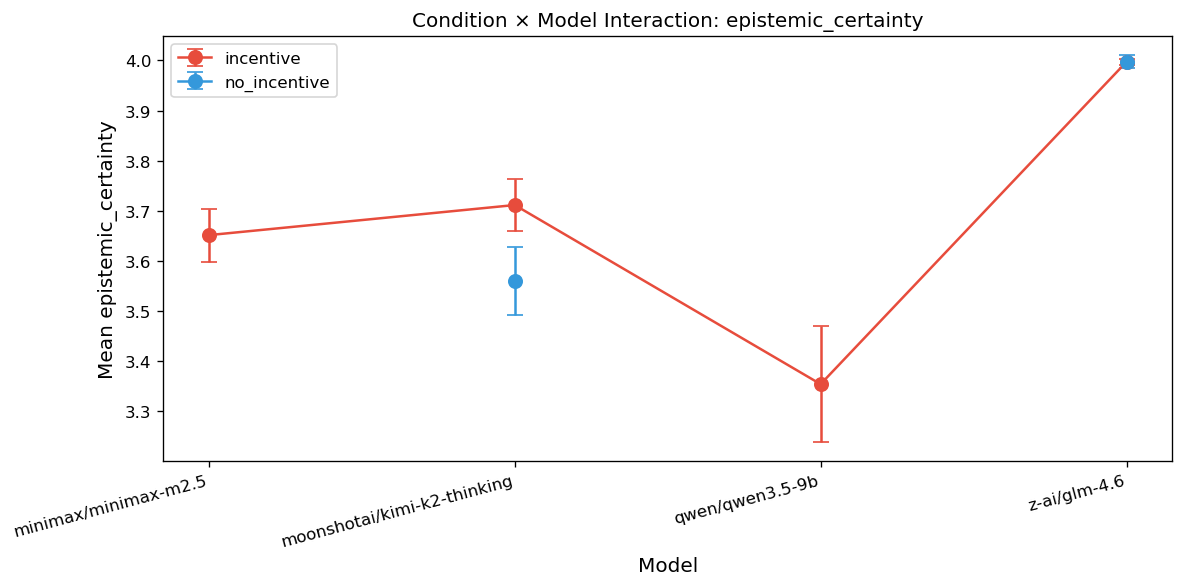

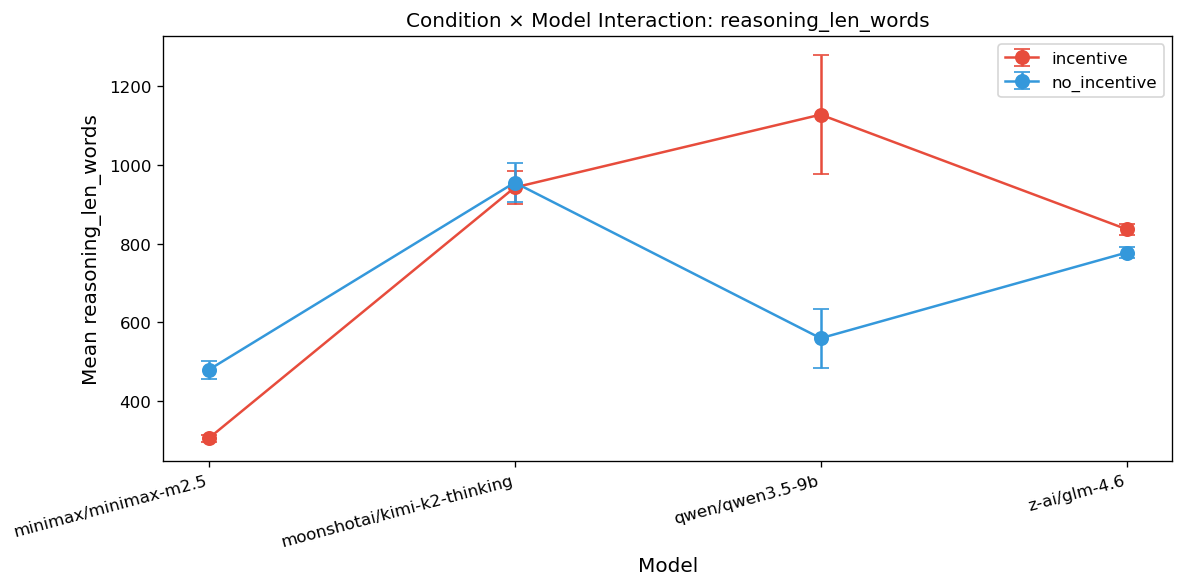

In [13]:
print("\n" + "=" * 80)
print("12. MIXED-EFFECTS MODELS (Condition → Outcome, controlling for model & experiment)")
print("=" * 80)

# For key outcome variables, fit mixed-effects models with random intercepts for
# model and experiment.

key_outcomes = [
    "treatment_awareness_score",
    "incentive_awareness_score",
    "epistemic_certainty",
    "social_desirability_total",
    "reasoning_style_internal_conflict",
    "role_adherence_ai_leakage",
    "role_adherence_role_immersion",
    "social_desirability_safe_answer_shift",
]

df_mixed = df.copy()
df_mixed["condition_bin"] = (df_mixed["condition"] == "incentive").astype(int)

mixed_results = []
for outcome in key_outcomes:
    df_tmp = df_mixed[["condition_bin", outcome, "model", "experiment_name"]].dropna()
    if len(df_tmp) < 50:
        print(f"  {outcome}: skipped (n={len(df_tmp)})")
        continue
    try:
        formula = f"{outcome} ~ condition_bin"
        md = smf.mixedlm(formula, df_tmp, groups=df_tmp["model"],
                          re_formula="~1",
                          vc_formula={"experiment_name": "0 + C(experiment_name)"})
        mdf = md.fit(reml=True)

        mixed_results.append({
            "outcome": outcome,
            "coef_condition": mdf.params.get("condition_bin", np.nan),
            "se": mdf.bse.get("condition_bin", np.nan),
            "z": mdf.tvalues.get("condition_bin", np.nan),
            "p_value": mdf.pvalues.get("condition_bin", np.nan),
            "n": len(df_tmp),
            "converged": mdf.converged
        })
        sig = "***" if mdf.pvalues.get("condition_bin", 1) < 0.001 else \
              "**" if mdf.pvalues.get("condition_bin", 1) < 0.01 else \
              "*" if mdf.pvalues.get("condition_bin", 1) < 0.05 else ""
        print(f"  {outcome:45s}  β={mdf.params.get('condition_bin', np.nan):+.4f}  "
              f"p={mdf.pvalues.get('condition_bin', np.nan):.6f} {sig}")
    except Exception as e:
        # Fallback: simpler model without vc_formula
        try:
            md = smf.mixedlm(formula, df_tmp, groups=df_tmp["model"])
            mdf = md.fit(reml=True)
            mixed_results.append({
                "outcome": outcome,
                "coef_condition": mdf.params.get("condition_bin", np.nan),
                "se": mdf.bse.get("condition_bin", np.nan),
                "z": mdf.tvalues.get("condition_bin", np.nan),
                "p_value": mdf.pvalues.get("condition_bin", np.nan),
                "n": len(df_tmp),
                "converged": mdf.converged
            })
            sig = "***" if mdf.pvalues.get("condition_bin", 1) < 0.001 else \
                  "**" if mdf.pvalues.get("condition_bin", 1) < 0.01 else \
                  "*" if mdf.pvalues.get("condition_bin", 1) < 0.05 else ""
            print(f"  {outcome:45s}  β={mdf.params.get('condition_bin', np.nan):+.4f}  "
                  f"p={mdf.pvalues.get('condition_bin', np.nan):.6f} {sig} (simplified)")
        except Exception as e2:
            print(f"  {outcome}: mixed model failed — {e2}")

df_mixed_res = pd.DataFrame(mixed_results)
if len(df_mixed_res) > 0:
    reject_m, p_adj_m, _, _ = multipletests(df_mixed_res["p_value"].fillna(1), method="fdr_bh")
    df_mixed_res["p_adjusted_fdr"] = p_adj_m
    df_mixed_res["significant_fdr05"] = reject_m
    df_mixed_res.to_csv("mixed_effects_results.csv", index=False)
    print("\n--- Mixed-effects results ---")
    print(df_mixed_res.to_string(index=False))

    # Forest plot of mixed-effects coefficients
    fig, ax = plt.subplots(figsize=(10, 6))
    df_plot = df_mixed_res.sort_values("coef_condition")
    y_pos = range(len(df_plot))
    colors_me = ["#e74c3c" if s else "#95a5a6" for s in df_plot["significant_fdr05"]]
    ax.barh(y_pos, df_plot["coef_condition"], xerr=df_plot["se"] * 1.96,
            color=colors_me, edgecolor="white", capsize=3)
    ax.axvline(0, color="black", linestyle="-", alpha=0.3)
    ax.set_yticks(y_pos)
    ax.set_yticklabels([textwrap.fill(o, 35) for o in df_plot["outcome"]])
    ax.set_xlabel("Coefficient (condition: incentive=1)")
    ax.set_title("Mixed-Effects: Condition Coefficient ± 95% CI\n(Red = FDR < 0.05)", fontsize=13)
    plt.tight_layout()
    plt.savefig("fig_15_mixed_effects_coefficients.png", bbox_inches="tight")
    plt.show()


# =============================================================================
# 13. INTERACTION ANALYSIS: CONDITION × MODEL
# =============================================================================
print("\n" + "=" * 80)
print("13. INTERACTION ANALYSIS: CONDITION × MODEL")
print("=" * 80)

df_inter = df.copy()
df_inter["condition_bin"] = (df_inter["condition"] == "incentive").astype(int)

interaction_results = []
for outcome in ["incentive_awareness_score", "social_desirability_total",
                 "epistemic_certainty", "treatment_awareness_score",
                 "role_adherence_role_immersion"]:
    df_tmp = df_inter[[outcome, "condition_bin", "model"]].dropna()
    if len(df_tmp) < 50:
        continue
    try:
        formula = f"{outcome} ~ condition_bin * C(model)"
        ols_model = smf.ols(formula, data=df_tmp).fit()
        # ANOVA table for interaction
        anova_table = sm.stats.anova_lm(ols_model, typ=2)
        print(f"\n--- {outcome} ---")
        print(anova_table.round(4).to_string())
        interaction_results.append({
            "outcome": outcome,
            "interaction_F": anova_table.loc["condition_bin:C(model)", "F"] if "condition_bin:C(model)" in anova_table.index else np.nan,
            "interaction_p": anova_table.loc["condition_bin:C(model)", "PR(>F)"] if "condition_bin:C(model)" in anova_table.index else np.nan,
            "R_squared": ols_model.rsquared,
            "R_squared_adj": ols_model.rsquared_adj,
        })
    except Exception as e:
        print(f"  {outcome}: interaction model failed — {e}")

df_inter_res = pd.DataFrame(interaction_results)
if len(df_inter_res) > 0:
    df_inter_res.to_csv("interaction_condition_model.csv", index=False)
    print("\n--- Interaction summary ---")
    print(df_inter_res.to_string(index=False))

# ── 13b. Interaction plots ──
for outcome in ["incentive_awareness_score", "social_desirability_total",
                 "epistemic_certainty"]:
    if outcome not in df.columns:
        continue
    fig, ax = plt.subplots(figsize=(10, 5))
    plot_data = df.groupby(["model", "condition"])[outcome].agg(["mean", "sem"]).reset_index()
    for cond, color in palette_condition.items():
        sub = plot_data[plot_data["condition"] == cond]
        ax.errorbar(sub["model"], sub["mean"], yerr=sub["sem"] * 1.96,
                     fmt="o-", color=color, label=cond, capsize=5, markersize=8)
    ax.set_title(f"Condition × Model Interaction: {outcome}", fontsize=12)
    ax.set_ylabel(f"Mean {outcome}")
    ax.set_xlabel("Model")
    ax.legend()
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.savefig(f"fig_16_interaction_{outcome}.png", bbox_inches="tight")
    plt.show()



14. TOPIC ANALYSIS
Total topic mentions: 7545
Unique topics: 2949

--- Top 20 topics (incentive) ---
topic
behavioral realism vs moral posturing                141
sleep deprivation as torture/cruel treatment         117
national security vs civil liberties                 117
national security vs human rights                     65
realism vs moral posturing in survey responding       60
privacy reducing social pressure                      58
public recognition and social rewards                 53
public recognition and social signaling               50
small monetary cost ($5)                              46
sleep deprivation as coercive interrogation           42
ticking time bomb framing                             34
sleep deprivation as torture                          34
public recognition and social approval                32
torture/sleep deprivation ethics                      31
national security vs human rights tradeoff            30
sleep deprivation as torture/inhumane


--- Topics significantly different between conditions (FDR < 0.05) ---
                                                      topic      chi2      p_value  count_inc  count_no  p_adjusted_fdr  significant_fdr05
                      behavioral realism vs moral posturing 81.091035 2.155557e-19        141         0    2.392668e-17               True
            realism vs moral posturing in survey responding 33.235917 8.162880e-09         60         0    4.530398e-07               True
                                   trust in local charities 32.154751 1.423681e-08          0        20    5.267620e-07               True
                   social desirability in survey responding 30.523671 3.298177e-08          4        26    9.152440e-07               True
                           privacy reducing social pressure 29.623319 5.246991e-08         58         1    1.164832e-06               True
                                privacy and social pressure 25.162108 5.270769e-07         11 

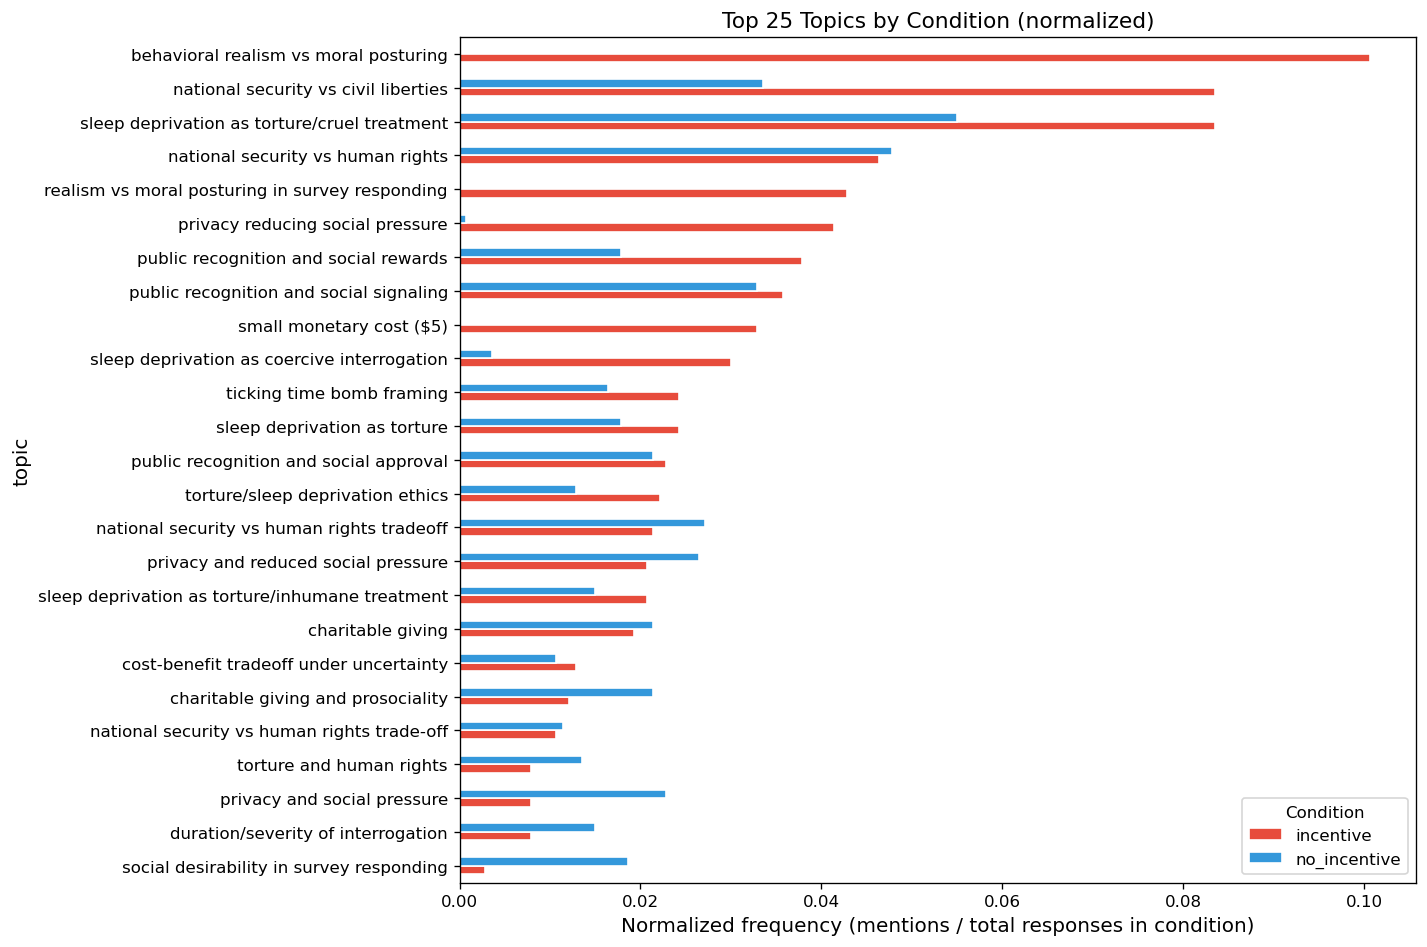

In [14]:
print("\n" + "=" * 80)
print("14. TOPIC ANALYSIS")
print("=" * 80)

# extracted_topics is a list/string of topics
df["topics_str"] = df["extracted_topics"].astype(str)

# Parse topics
import ast

def parse_topics(x):
    """Parse topic strings to list."""
    if pd.isna(x):
        return []
    x = str(x).strip()
    try:
        result = ast.literal_eval(x)
        if isinstance(result, list):
            return [str(t).strip().lower() for t in result]
    except:
        pass
    # fallback: split by comma
    return [t.strip().lower().strip("'\"[]") for t in x.split(",") if t.strip()]

df["topics_list"] = df["extracted_topics"].apply(parse_topics)

# Explode topics
df_topics = df[["condition", "model", "experiment_name", "topics_list"]].explode("topics_list")
df_topics = df_topics.rename(columns={"topics_list": "topic"})
df_topics = df_topics[df_topics["topic"].notna() & (df_topics["topic"] != "")]

print(f"Total topic mentions: {len(df_topics)}")
print(f"Unique topics: {df_topics['topic'].nunique()}")

# Top topics by condition
for cond in ["incentive", "no_incentive"]:
    sub = df_topics[df_topics["condition"] == cond]
    top = sub["topic"].value_counts().head(20)
    print(f"\n--- Top 20 topics ({cond}) ---")
    print(top.to_string())

# ── 14a. Topic frequency comparison ──
topic_counts = pd.crosstab(df_topics["topic"], df_topics["condition"])
topic_counts["total"] = topic_counts.sum(axis=1)
topic_counts = topic_counts[topic_counts["total"] >= 10].sort_values("total", ascending=False)

# Chi-squared per topic
topic_chi2_results = []
for topic in topic_counts.index:
    ct = pd.crosstab(df_topics["topic"] == topic, df_topics["condition"])
    if ct.shape == (2, 2):
        chi2, p, _, _ = chi2_contingency(ct)
        topic_chi2_results.append({
            "topic": topic, "chi2": chi2, "p_value": p,
            "count_inc": topic_counts.loc[topic, "incentive"] if "incentive" in topic_counts.columns else 0,
            "count_no": topic_counts.loc[topic, "no_incentive"] if "no_incentive" in topic_counts.columns else 0,
        })

df_topic_chi2 = pd.DataFrame(topic_chi2_results).sort_values("p_value")
if len(df_topic_chi2) > 0:
    reject_t, p_adj_t, _, _ = multipletests(df_topic_chi2["p_value"], method="fdr_bh")
    df_topic_chi2["p_adjusted_fdr"] = p_adj_t
    df_topic_chi2["significant_fdr05"] = reject_t
    df_topic_chi2.to_csv("topic_chi2_comparison.csv", index=False)
    print("\n--- Topics significantly different between conditions (FDR < 0.05) ---")
    sig_topics = df_topic_chi2[df_topic_chi2["significant_fdr05"]]
    print(sig_topics.to_string(index=False))

# ── 14b. Topic frequency bar chart ──
top_topics_overall = df_topics["topic"].value_counts().head(25).index
topic_freq = (
    df_topics[df_topics["topic"].isin(top_topics_overall)]
    .groupby(["topic", "condition"])
    .size()
    .unstack(fill_value=0)
)
# Normalize by condition size
n_inc_total = (df["condition"] == "incentive").sum()
n_no_total = (df["condition"] == "no_incentive").sum()
topic_freq_norm = topic_freq.copy()
if "incentive" in topic_freq_norm.columns:
    topic_freq_norm["incentive"] = topic_freq_norm["incentive"] / n_inc_total
if "no_incentive" in topic_freq_norm.columns:
    topic_freq_norm["no_incentive"] = topic_freq_norm["no_incentive"] / n_no_total
topic_freq_norm = topic_freq_norm.sort_values(
    topic_freq_norm.columns[0], ascending=True
)

fig, ax = plt.subplots(figsize=(12, 8))
topic_freq_norm.plot(kind="barh", ax=ax,
                      color=[palette_condition.get(c, "gray") for c in topic_freq_norm.columns],
                      edgecolor="white")
ax.set_xlabel("Normalized frequency (mentions / total responses in condition)")
ax.set_title("Top 25 Topics by Condition (normalized)", fontsize=13)
ax.legend(title="Condition")
plt.tight_layout()
plt.savefig("fig_17_topic_frequencies.png", bbox_inches="tight")
plt.show()




15. EMOTION ANALYSIS

--- Emotion distribution by Model × Condition ---
affective_state_dominant_emotion          empathy_pity  fear_anxiety   hope  indignation   none
model                       condition                                                          
minimax/minimax-m2.5        incentive            0.000         0.026  0.014        0.000  0.960
                            no_incentive         0.000         0.000  0.000        0.000  1.000
moonshotai/kimi-k2-thinking incentive            0.000         0.106  0.000        0.000  0.894
                            no_incentive         0.026         0.014  0.060        0.003  0.897
qwen/qwen3.5-9b             incentive            0.000         0.131  0.000        0.000  0.869
                            no_incentive         0.000         0.000  0.000        0.000  1.000
z-ai/glm-4.6                incentive            0.000         0.431  0.026        0.000  0.543
                            no_incentive         0.097         

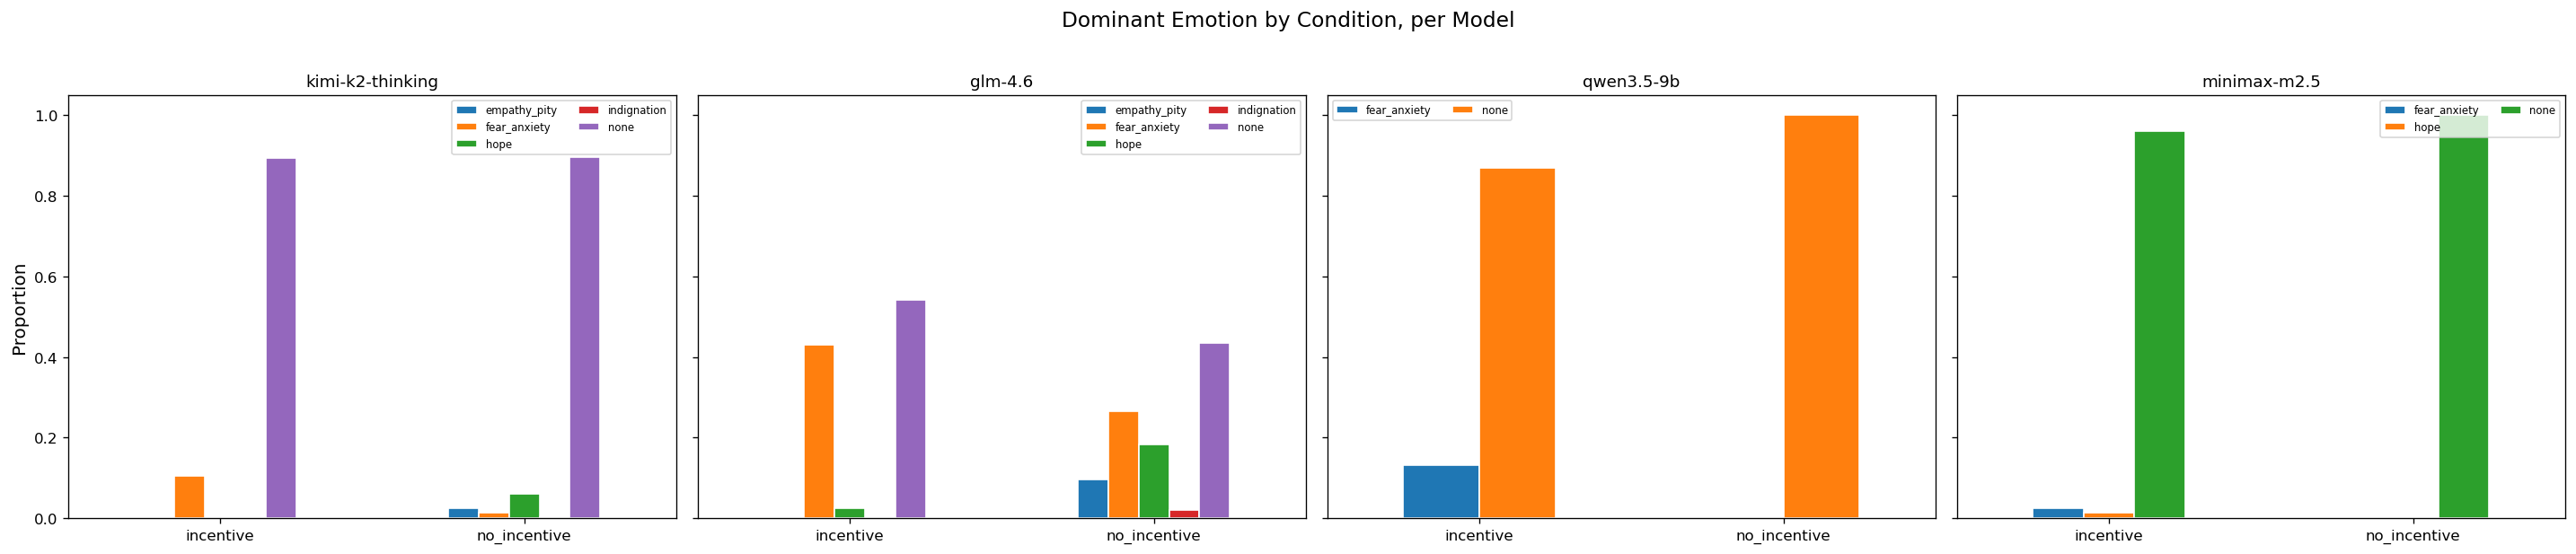

In [15]:
print("\n" + "=" * 80)
print("15. EMOTION ANALYSIS")
print("=" * 80)

# Emotion × Condition × Model
emotion_ct = pd.crosstab(
    [df["model"], df["condition"]],
    df["affective_state_dominant_emotion"],
    normalize="index"
)
print("\n--- Emotion distribution by Model × Condition ---")
print(emotion_ct.round(3).to_string())

fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 5), sharey=True)
if len(models) == 1:
    axes = [axes]
for i, model_name in enumerate(models):
    ax = axes[i]
    sub = df[df["model"] == model_name]
    ct = pd.crosstab(sub["condition"], sub["affective_state_dominant_emotion"], normalize="index")
    ct.plot(kind="bar", ax=ax, edgecolor="white")
    ax.set_title(model_name.split("/")[-1], fontsize=11)
    ax.set_ylabel("Proportion" if i == 0 else "")
    ax.set_xlabel("")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    ax.legend(fontsize=7, ncol=2)
plt.suptitle("Dominant Emotion by Condition, per Model", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("fig_18_emotion_by_model_condition.png", bbox_inches="tight")
plt.show()


16. REASONING STRATEGY ANALYSIS

Chi-squared test for reasoning strategy × condition:
  χ² = 550.760, p = 0.000000
reasoning_style_primary_strategy  heuristic-shortcut  logical-deductive  none  social-normative
condition                                                                                      
incentive                                        148                943   207               102
no_incentive                                       3                680   713                 4

--- Strategy proportions ---
reasoning_style_primary_strategy          heuristic-shortcut  logical-deductive   none  social-normative
model                       condition                                                                   
minimax/minimax-m2.5        incentive                  0.137              0.749  0.000             0.114
                            no_incentive               0.000              0.000  1.000             0.000
moonshotai/kimi-k2-thinking incentive             

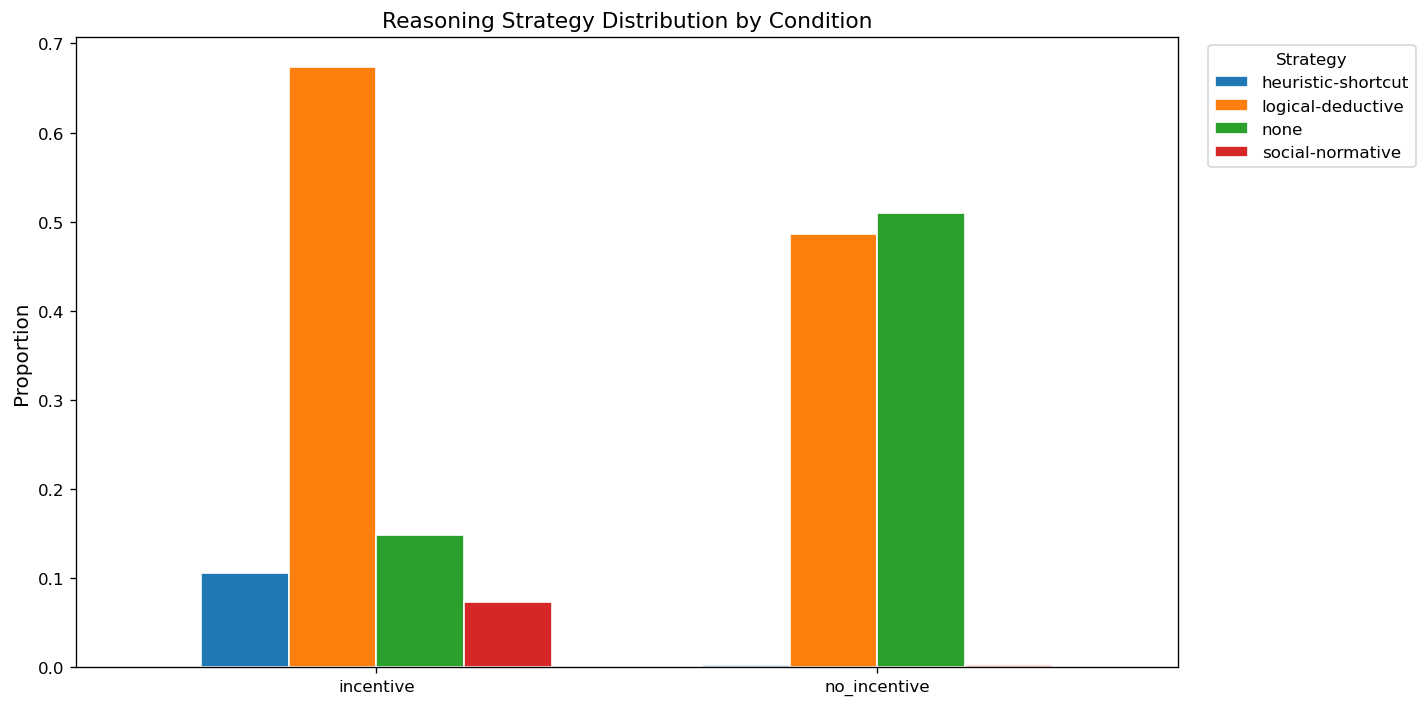

In [16]:
print("\n" + "=" * 80)
print("16. REASONING STRATEGY ANALYSIS")
print("=" * 80)

strat_ct = pd.crosstab(df["condition"], df["reasoning_style_primary_strategy"])
chi2_strat, p_strat, dof_strat, _ = chi2_contingency(strat_ct)
print(f"\nChi-squared test for reasoning strategy × condition:")
print(f"  χ² = {chi2_strat:.3f}, p = {p_strat:.6f}")
print(strat_ct.to_string())

# Strategy proportions by condition and model
strat_norm = pd.crosstab(
    [df["model"], df["condition"]],
    df["reasoning_style_primary_strategy"],
    normalize="index"
)
print("\n--- Strategy proportions ---")
print(strat_norm.round(3).to_string())

fig, ax = plt.subplots(figsize=(12, 6))
strat_plot = pd.crosstab(df["condition"], df["reasoning_style_primary_strategy"], normalize="index")
strat_plot.plot(kind="bar", ax=ax, edgecolor="white", width=0.7)
ax.set_title("Reasoning Strategy Distribution by Condition", fontsize=13)
ax.set_ylabel("Proportion")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="Strategy", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("fig_19_reasoning_strategy.png", bbox_inches="tight")
plt.show()

In [17]:
print("\n" + "=" * 80)
print("17. ORDINAL LOGISTIC REGRESSION (key outcomes)")
print("=" * 80)

# For ordinal outcomes, use ordered logit via statsmodels
from statsmodels.miscmodels.ordinal_model import OrderedModel

ordinal_outcomes = [
    "incentive_awareness_score",
    "treatment_awareness_score",
    "epistemic_certainty",
    "social_desirability_normative_orientation",
    "social_desirability_fear_of_judgment",
    "social_desirability_safe_answer_shift",
    "role_adherence_role_immersion",
]

df_ord = df.copy()
df_ord["condition_bin"] = (df_ord["condition"] == "incentive").astype(int)
# Create model dummies
for m_idx, m_name in enumerate(models[1:], 1):
    df_ord[f"model_{m_idx}"] = (df_ord["model"] == m_name).astype(int)
model_dummy_cols = [f"model_{i}" for i in range(1, len(models))]

ordinal_reg_results = []
for outcome in ordinal_outcomes:
    df_tmp = df_ord[["condition_bin", outcome] + model_dummy_cols].dropna()
    if len(df_tmp) < 50 or df_tmp[outcome].nunique() < 2:
        print(f"  {outcome}: skipped")
        continue
    try:
        exog = df_tmp[["condition_bin"] + model_dummy_cols].astype(float)
        endog = df_tmp[outcome].astype(float)
        mod = OrderedModel(endog, exog, distr="logit")
        res = mod.fit(method="bfgs", disp=False)
        print(f"\n--- {outcome} ---")
        print(res.summary())

        coef_cond = res.params.get("condition_bin", np.nan)
        p_cond = res.pvalues.get("condition_bin", np.nan)
        ordinal_reg_results.append({
            "outcome": outcome,
            "coef_condition": coef_cond,
            "odds_ratio": np.exp(coef_cond) if not np.isnan(coef_cond) else np.nan,
            "p_value": p_cond,
            "n": len(df_tmp),
            "converged": res.mle_retvals.get("converged", None) if hasattr(res, "mle_retvals") else None
        })
    except Exception as e:
        print(f"  {outcome}: ordered logit failed — {e}")

df_ordinal_res = pd.DataFrame(ordinal_reg_results)
if len(df_ordinal_res) > 0:
    df_ordinal_res.to_csv("ordinal_logistic_results.csv", index=False)
    print("\n--- Ordinal Logistic Regression: Condition coefficient ---")
    print(df_ordinal_res.to_string(index=False))



17. ORDINAL LOGISTIC REGRESSION (key outcomes)



--- incentive_awareness_score ---
                                 OrderedModel Results                                
Dep. Variable:     incentive_awareness_score   Log-Likelihood:                -918.17
Model:                          OrderedModel   AIC:                             1850.
Method:                   Maximum Likelihood   BIC:                             1889.
Date:                       Wed, 15 Apr 2026                                         
Time:                               21:33:35                                         
No. Observations:                       1880                                         
Df Residuals:                           1873                                         
Df Model:                                  4                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
condition_bin    20.2247   


--- treatment_awareness_score ---
                                 OrderedModel Results                                
Dep. Variable:     treatment_awareness_score   Log-Likelihood:                -1888.1
Model:                          OrderedModel   AIC:                             3790.
Method:                   Maximum Likelihood   BIC:                             3829.
Date:                       Wed, 15 Apr 2026                                         
Time:                               21:33:36                                         
No. Observations:                       1880                                         
Df Residuals:                           1873                                         
Df Model:                                  4                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
condition_bin    -0.2363   


--- epistemic_certainty ---
                              OrderedModel Results                             
Dep. Variable:     epistemic_certainty   Log-Likelihood:                -959.84
Model:                    OrderedModel   AIC:                             1934.
Method:             Maximum Likelihood   BIC:                             1972.
Date:                 Wed, 15 Apr 2026                                         
Time:                         21:33:36                                         
No. Observations:                 1880                                         
Df Residuals:                     1873                                         
Df Model:                            4                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
condition_bin     0.4565      0.160      2.854      0.004       0.143       0.770
model


--- social_desirability_normative_orientation ---
                                         OrderedModel Results                                        
Dep. Variable:     social_desirability_normative_orientation   Log-Likelihood:                -962.94
Model:                                          OrderedModel   AIC:                             1936.
Method:                                   Maximum Likelihood   BIC:                             1964.
Date:                                       Wed, 15 Apr 2026                                         
Time:                                               21:33:36                                         
No. Observations:                                       1880                                         
Df Residuals:                                           1875                                         
Df Model:                                                  4                                         
                    coef    std


--- social_desirability_fear_of_judgment ---
                                      OrderedModel Results                                      
Dep. Variable:     social_desirability_fear_of_judgment   Log-Likelihood:                -1199.1
Model:                                     OrderedModel   AIC:                             2410.
Method:                              Maximum Likelihood   BIC:                             2444.
Date:                                  Wed, 15 Apr 2026                                         
Time:                                          21:33:37                                         
No. Observations:                                  1880                                         
Df Residuals:                                      1874                                         
Df Model:                                             4                                         
                    coef    std err          z      P>|z|      [0.025      0.975]


--- social_desirability_safe_answer_shift ---
                                       OrderedModel Results                                      
Dep. Variable:     social_desirability_safe_answer_shift   Log-Likelihood:                -1444.7
Model:                                      OrderedModel   AIC:                             2901.
Method:                               Maximum Likelihood   BIC:                             2935.
Date:                                   Wed, 15 Apr 2026                                         
Time:                                           21:33:37                                         
No. Observations:                                   1880                                         
Df Residuals:                                       1874                                         
Df Model:                                              4                                         
                    coef    std err          z      P>|z|      [0.025  


--- role_adherence_role_immersion ---
                                   OrderedModel Results                                  
Dep. Variable:     role_adherence_role_immersion   Log-Likelihood:                -831.69
Model:                              OrderedModel   AIC:                             1675.
Method:                       Maximum Likelihood   BIC:                             1709.
Date:                           Wed, 15 Apr 2026                                         
Time:                                   21:33:37                                         
No. Observations:                           1880                                         
Df Residuals:                               1874                                         
Df Model:                                      4                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------


18. COMPREHENSIVE SUMMARY TABLE



                                     variable    type  mean_incentive  std_incentive  median_incentive  mean_no_incentive  std_no_incentive  median_no_incentive  diff_means  cohens_d      p_value  p_adjusted_fdr  effect_size  significant_fdr05
                    incentive_awareness_score ordinal        2.405700       0.622321               2.0           0.000000          0.000000                  0.0    2.405700  4.852180 0.000000e+00    0.000000e+00    -0.989103               True
    social_desirability_normative_orientation ordinal        1.248952       0.432587               1.0           1.721980          0.448350                  2.0   -0.473027 -1.078959 6.233512e-89    1.766162e-88     0.473027               True
         social_desirability_fear_of_judgment ordinal        1.343671       0.568389               1.0           0.812227          0.423055                  1.0    0.531444  1.021947 2.383840e-83    5.789325e-83    -0.453281               True
        social_desirabi

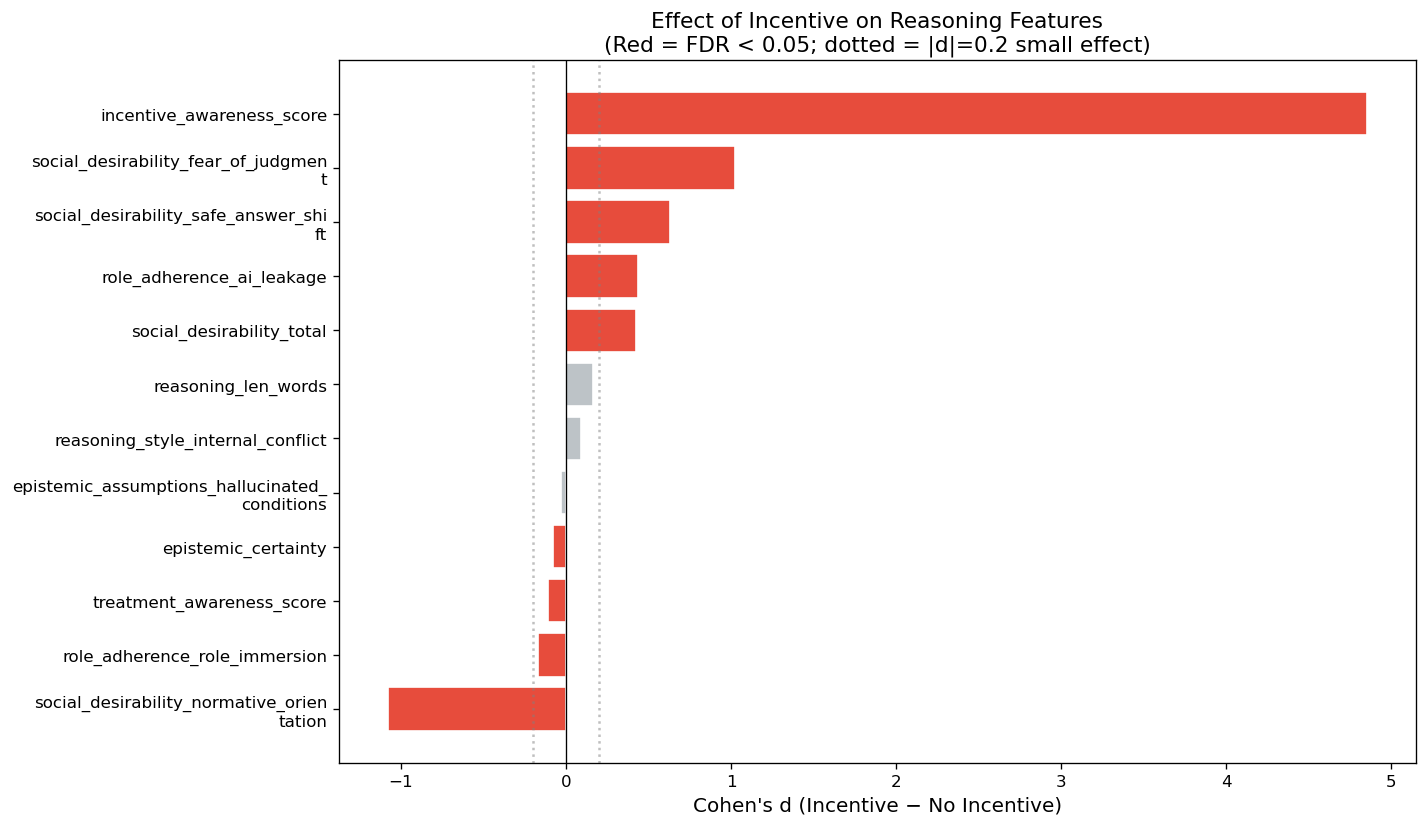

In [18]:
print("\n" + "=" * 80)
print("18. COMPREHENSIVE SUMMARY TABLE")
print("=" * 80)

summary_rows = []
for var in ordinal_vars + binary_vars + ["social_desirability_total"]:
    inc_vals = df.loc[df["condition"] == "incentive", var].dropna()
    no_vals = df.loc[df["condition"] == "no_incentive", var].dropna()
    row = {
        "variable": var,
        "type": "ordinal" if var in ordinal_vars else ("binary" if var in binary_vars else "derived"),
        "mean_incentive": inc_vals.mean(),
        "std_incentive": inc_vals.std(),
        "median_incentive": inc_vals.median(),
        "mean_no_incentive": no_vals.mean(),
        "std_no_incentive": no_vals.std(),
        "median_no_incentive": no_vals.median(),
        "diff_means": inc_vals.mean() - no_vals.mean(),
        "cohens_d": (inc_vals.mean() - no_vals.mean()) / np.sqrt(
            ((len(inc_vals) - 1) * inc_vals.std() ** 2 + (len(no_vals) - 1) * no_vals.std() ** 2) /
            (len(inc_vals) + len(no_vals) - 2)
        ) if (inc_vals.std() > 0 or no_vals.std() > 0) else 0,
    }
    # Find test result
    test_row = df_tests[df_tests["variable"] == var]
    if len(test_row) > 0:
        row["p_value"] = test_row.iloc[0]["p_value"]
        row["p_adjusted_fdr"] = test_row.iloc[0]["p_adjusted_fdr"]
        row["effect_size"] = test_row.iloc[0]["effect_size_r"]
        row["significant_fdr05"] = test_row.iloc[0]["significant_fdr05"]
    summary_rows.append(row)

df_summary = pd.DataFrame(summary_rows)
df_summary = df_summary.sort_values("p_value")
df_summary.to_csv("comprehensive_summary.csv", index=False)

print("\n" + df_summary.to_string(index=False))

# ── 18b. Publication-ready summary plot ──
fig, ax = plt.subplots(figsize=(12, 7))
df_plot = df_summary.sort_values("cohens_d")
colors_summary = ["#e74c3c" if s else "#bdc3c7"
                   for s in df_plot.get("significant_fdr05", [False] * len(df_plot))]
bars = ax.barh(range(len(df_plot)), df_plot["cohens_d"], color=colors_summary, edgecolor="white")
ax.axvline(0, color="black", linewidth=0.8)
ax.axvline(-0.2, color="gray", linestyle=":", alpha=0.5)
ax.axvline(0.2, color="gray", linestyle=":", alpha=0.5)
ax.set_yticks(range(len(df_plot)))
ax.set_yticklabels([textwrap.fill(v, 35) for v in df_plot["variable"]])
ax.set_xlabel("Cohen's d (Incentive − No Incentive)")
ax.set_title("Effect of Incentive on Reasoning Features\n(Red = FDR < 0.05; dotted = |d|=0.2 small effect)",
             fontsize=13)
plt.tight_layout()
plt.savefig("fig_20_summary_effect_sizes.png", bbox_inches="tight")
plt.show()


In [19]:
print("\n" + "=" * 80)
print("19. FILES EXPORTED")
print("=" * 80)

export_files = [
    "statistical_tests_summary.csv",
    "within_model_tests.csv",
    "within_experiment_tests.csv",
    "logistic_regression_coefficients.csv",
    "random_forest_feature_importance.csv",
    "gradient_boosting_feature_importance.csv",
    "mixed_effects_results.csv",
    "interaction_condition_model.csv",
    "topic_chi2_comparison.csv",
    "ordinal_logistic_results.csv",
    "comprehensive_summary.csv",
]

for f in export_files:
    try:
        _ = pd.read_csv(f)
        print(f"  ✓ {f}")
    except:
        print(f"  ✗ {f} (not created)")

print("\nFigures saved: fig_01 through fig_20")
print("\n" + "=" * 80)
print("ANALYSIS COMPLETE")
print("=" * 80)


19. FILES EXPORTED
  ✓ statistical_tests_summary.csv
  ✓ within_model_tests.csv
  ✓ within_experiment_tests.csv
  ✗ logistic_regression_coefficients.csv (not created)
  ✓ random_forest_feature_importance.csv
  ✓ gradient_boosting_feature_importance.csv
  ✓ mixed_effects_results.csv
  ✗ interaction_condition_model.csv (not created)
  ✓ topic_chi2_comparison.csv
  ✓ ordinal_logistic_results.csv
  ✓ comprehensive_summary.csv

Figures saved: fig_01 through fig_20

ANALYSIS COMPLETE
